# Exploratory Data Analysis

Engagement and purchase patterns by audience match, ad type, platform, day and hour.

In [1]:
from pathlib import Path
import pandas as pd

# works from notebooks/ (Jupyter) or the repo root (e.g. Colab after git clone + %cd)
DATA_DIR = Path('../data') if Path('../data').exists() else Path('data')

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
ad_events_df = pd.read_csv(DATA_DIR / 'ad_events.csv')
ads_df = pd.read_csv(DATA_DIR / 'ads.csv')
users_df = pd.read_csv(DATA_DIR / 'users.csv')
campaigns_df = pd.read_csv(DATA_DIR / 'campaigns.csv')

In [4]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
df_merged_prep = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')
df_merged_prep['timestamp'] = pd.to_datetime(df_merged_prep['timestamp'])
df_merged_prep['hour_of_day'] = df_merged_prep['timestamp'].dt.hour

# New Table

In [5]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
users_df_clean = users_df.drop_duplicates(subset=['user_id'])
campaigns_df_clean = campaigns_df.drop_duplicates(subset=['campaign_id'])
initial_rows = len(ad_events_df)

df_merged = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')
df_merged = pd.merge(df_merged, users_df_clean, on='user_id', how='left', suffixes=('_ad', '_user'))
df_merged = pd.merge(
    df_merged,
    campaigns_df_clean[['campaign_id', 'name']],
    on='campaign_id',
    how='left'
).rename(columns={'name': 'campaign_name'})

def clean_interests(interests_str):
    if isinstance(interests_str, str):
        return set([item.strip() for item in interests_str.replace('"', '').split(',') if item.strip()])
    return set()

df_merged['target_interests_set'] = df_merged['target_interests'].apply(clean_interests)
df_merged['user_interests_set'] = df_merged['interests'].apply(clean_interests)

def calculate_age_match(row):
    target = row['target_age_group']
    user_age_group = row['age_group']
    if target == 'All':
        return True
    return target == user_age_group

df_merged['IsMatch (AGE)'] = df_merged.apply(calculate_age_match, axis=1)

df_merged['IsMatch (Interests)'] = df_merged.apply(
    lambda row: len(row['target_interests_set'].intersection(row['user_interests_set'])) > 0,
    axis=1
)

final_columns = [
    'event_id', 'ad_id', 'user_id', 'event_type',
    'campaign_id', 'campaign_name',
    'ad_platform', 'ad_type', 'target_gender', 'target_age_group', 'target_interests',
    'user_gender', 'user_age', 'age_group', 'interests',
    'IsMatch (AGE)', 'IsMatch (Interests)'
]

df_final_analysis = df_merged[final_columns]

In [6]:
df_final_analysis

,event_id,ad_id,user_id,event_type,campaign_id,campaign_name,ad_platform,ad_type,target_gender,target_age_group,target_interests,user_gender,user_age,age_group,interests,IsMatch (AGE),IsMatch (Interests)
0,1,197,2359b,Like,9,Campaign_9_Launch,Facebook,Stories,All,All,"lifestyle, gaming",Female,24,18-24,"gaming, food",True,True
1,2,51,f9c67,Share,26,Campaign_26_Winter,Instagram,Carousel,All,18-24,photography,Female,30,25-34,"photography, finance",False,True
2,3,46,5b868,Impression,10,Campaign_10_Winter,Instagram,Carousel,All,35-44,"technology, travel",Male,20,18-24,"fashion, sports, travel",False,True
3,4,166,3d440,Impression,14,Campaign_14_Summer,Instagram,Image,All,All,fashion,Female,18,18-24,"food, art",True,False
4,5,52,68f1a,Impression,2,Campaign_2_Launch,Instagram,Stories,Female,35-44,"health, lifestyle",Male,58,55-65,"finance, lifestyle",False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399995,399996,132,3cb8c,Impression,1,Campaign_1_Launch,Facebook,Carousel,Female,18-24,news,Male,16,16-17,"fashion, fitness, photography",False,False
399996,399997,200,fe0e3,Impression,44,Campaign_44_Q3,Instagram,Carousel,Male,18-24,photography,Male,29,25-34,"photography, art",False,True
399997,399998,2,a08c1,Click,33,Campaign_33_Summer,Facebook,Stories,All,25-34,"travel, photography",Female,28,25-34,"photography, finance, lifestyle",True,True
399998,399999,109,4f0cf,Impression,8,Campaign_8_Q3,Facebook,Stories,All,35-44,"travel, fashion",Other,27,25-34,"food, fashion",False,True


 ตารางโชว์ถึง ads ทั้งหมดที่ถูกยิงไปหา user โดย แต่ row จะบอก event_id	/ ad_id	/user_id /	event_type /	campaign_id	 / campaign_name /	ad_platform	/ad_type /	target_gender /	target_age_group /	target_interest /	user_gender	/user_age / age_group /	user_interests /	IsMatch (AGE) /	IsMatch (Interests)

------------------------------------------------------------------------------------------

 IsMatch (AGE) /	IsMatch (Interests) โดยที่ True จะบอกว่าตรงกับ Target ส่วน False คือไม่ตรง

# PLT

In [7]:
plt.figure(figsize=(12, 6))
plt.style.use('seaborn-v0_8-whitegrid')
plt.suptitle('Comparison of Age and Interest Matching', fontsize=16, fontweight='bold')

Text(0.5, 0.98, 'Comparison of Age and Interest Matching')

<Figure size 1200x600 with 0 Axes>

/tmp/ipykernel_588/1827857243.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_group_counts.index, y=age_group_counts.values, palette='coolwarm')


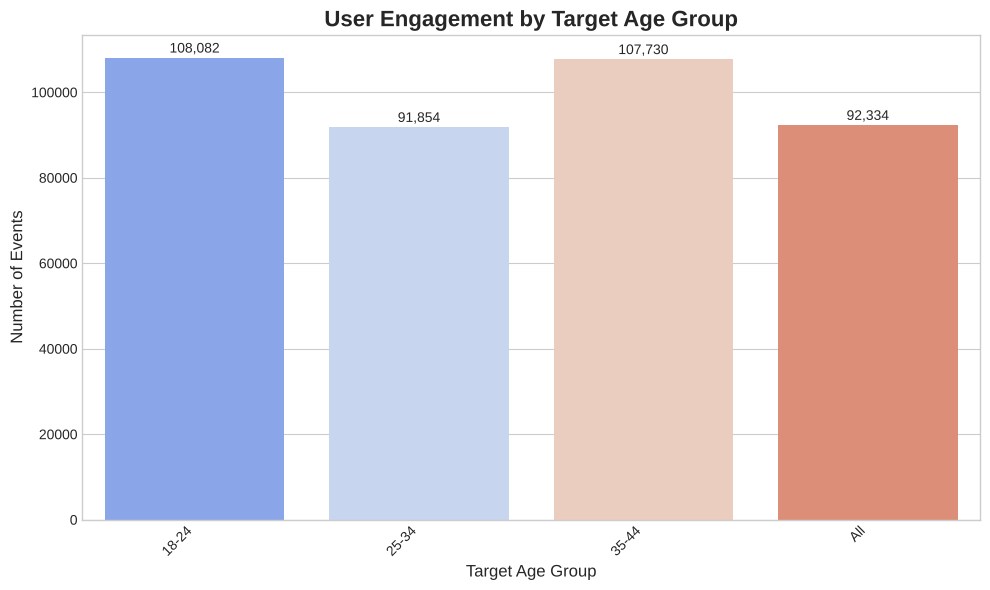

In [8]:
plt.figure(figsize=(10, 6))
plt.title('User Engagement by Target Age Group', fontsize=16, fontweight='bold')
age_group_counts = df_final_analysis['target_age_group'].value_counts().sort_index()
sns.barplot(x=age_group_counts.index, y=age_group_counts.values, palette='coolwarm')
plt.ylabel('Number of Events', fontsize=12)
plt.xlabel('Target Age Group', fontsize=12)
plt.xticks(rotation=45, ha='right')
for index, value in enumerate(age_group_counts.values):
    plt.text(index, value + 500, f'{value:,}', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

กราฟโชว์ถึงการมีส่วนร่วมของ USER โดยใช้ เป้าหมายกลุ่มอายุเป็นตัวกำหนด สังเกตุอายุช่วง 18-24 และ 35-44 จะมีส่วนร่วมสูงเนื่องจากเป็นช่วงวัยที่ยังไม่เครียดเรื่องงานมากหรือสามารถใช้จ่ายได้โดยไม่กังวลเรื่องหนี้สินได้

-----------------------------------------------------------------------------------------------------------------------------------

/tmp/ipykernel_588/352187340.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ad_type_counts.index, y=ad_type_counts.values, palette='plasma')


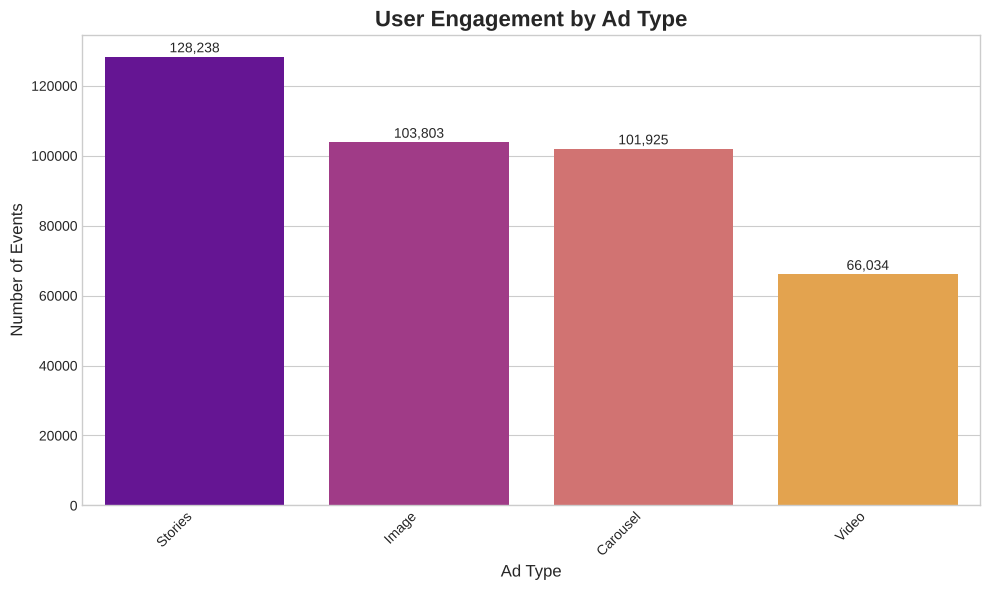

In [9]:
plt.figure(figsize=(10, 6))
plt.title('User Engagement by Ad Type', fontsize=16, fontweight='bold')
ad_type_counts = df_final_analysis['ad_type'].value_counts()
sns.barplot(x=ad_type_counts.index, y=ad_type_counts.values, palette='plasma')
plt.ylabel('Number of Events', fontsize=12)
plt.xlabel('Ad Type', fontsize=12)
plt.xticks(rotation=45, ha='right')
for index, value in enumerate(ad_type_counts.values):
    plt.text(index, value + 500, f'{value:,}', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()


กราฟโชว์การมีส่วนร่วมของ User โดยใช้ประเภทของโฆษณาเป็นตัวกำหนด จะสังเกตุได้ว่าโฆษณาประเภททีั่ได้ความนิยมสูงมักจะเป็นโฆษณาที่ไม่ใช้เวลาในการดูยาวมาก เช่น Stories , รูปภาพ และ แท่นหมุนสินค้า โดยโฆษณาประเภท Video จะน้อยสุดเนื่องจากมีความยาวมากเกินไปหากมีความดึงดูดน้อย USER ก็จะไม่สนใจได้

---------------------------------------------------------------------------------------------------------------

/tmp/ipykernel_588/1644900692.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=platform_counts.index, y=platform_counts.values, palette='viridis')


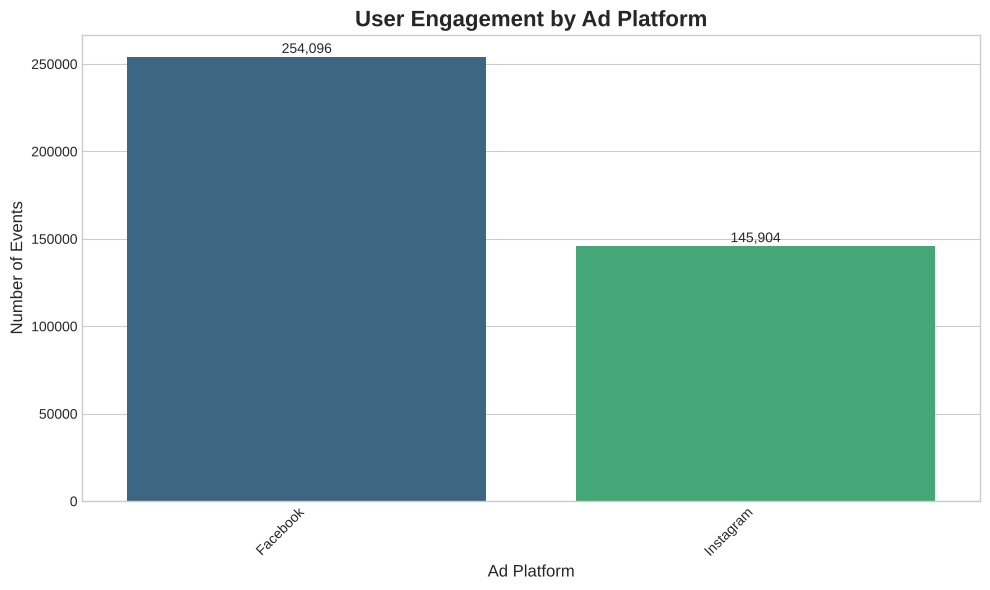

In [10]:
plt.figure(figsize=(10, 6))
plt.title('User Engagement by Ad Platform', fontsize=16, fontweight='bold')
platform_counts = df_final_analysis['ad_platform'].value_counts()
sns.barplot(x=platform_counts.index, y=platform_counts.values, palette='viridis')
plt.ylabel('Number of Events', fontsize=12)
plt.xlabel('Ad Platform', fontsize=12)
plt.xticks(rotation=45, ha='right')
for index, value in enumerate(platform_counts.values):
    plt.text(index, value + 500, f'{value:,}', ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()

กราฟโชว์การมีส่วนร่วมของ User โดยดูจาก platform สังเกตุได้ว่า user จะใช้ facebook มากกว่า ig เกือบเท่าตัว

--------------------------------------------------------------------------------

/tmp/ipykernel_588/654186334.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=interest_match_counts.index, y=interest_match_counts.values, palette='Oranges_d')


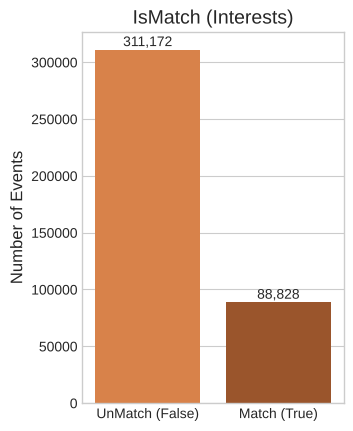


Purchase Rates by Interest Match Status:
| Category        |   Total Users |   Purchase Users |   Purchase Percentage (%) |
|:----------------|--------------:|-----------------:|--------------------------:|
| Match (True)    |         88828 |              452 |                  0.508849 |
| UnMatch (False) |        311172 |             1579 |                  0.507436 |


In [11]:
plt.subplot(1, 2, 2)
interest_match_counts = df_final_analysis['IsMatch (Interests)'].value_counts()
interest_match_counts.rename(index={True: 'Match (True)', False: 'UnMatch (False)'}, inplace=True)
sns.barplot(x=interest_match_counts.index, y=interest_match_counts.values, palette='Oranges_d')
plt.title('IsMatch (Interests)', fontsize=14)
plt.ylabel('Number of Events', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=0)
for index, value in enumerate(interest_match_counts.values):
    plt.text(index, value + 500, f'{value:,}', ha='center', va='bottom', fontsize=10)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

purchase_events = df_final_analysis[df_final_analysis['event_type'] == 'Purchase']
match_purchase_count = purchase_events['IsMatch (Interests)'].value_counts().get(True, 0)
total_match_count = df_final_analysis['IsMatch (Interests)'].value_counts().get(True, 0)
if total_match_count > 0:
    purchase_from_match_percentage = (match_purchase_count / total_match_count) * 100
else:
    purchase_from_match_percentage = 0
summary_data = {
    'Category': ['Match (True)', 'UnMatch (False)'],
    'Total Users': [df_final_analysis['IsMatch (Interests)'].value_counts().get(True, 0),
                    df_final_analysis['IsMatch (Interests)'].value_counts().get(False, 0)],
    'Purchase Users': [purchase_events['IsMatch (Interests)'].value_counts().get(True, 0),
                       purchase_events['IsMatch (Interests)'].value_counts().get(False, 0)]
}

df_summary = pd.DataFrame(summary_data)
df_summary['Purchase Percentage (%)'] = (df_summary['Purchase Users'] / df_summary['Total Users']) * 100
df_summary.set_index('Category', inplace=True)

print("\nPurchase Rates by Interest Match Status:")
print(df_summary.to_markdown())

กราฟนี้โชว์ว่าโฆษณาที่ยิงไปและ user ที่มีส่วนร่วมกับ ads นั้นมีความ เข้ากันกับ targetของความสนใจ เท่าไหร่
และดูอีกว่าจำนวน user ถ้าเทียบกันว่าอัตราที่ user จากการซื้อนับเป็นกี่เปอร์เซ็นจากจำนวนทั้งหมดที่เห็นโฆษณา สังเกตุว่าโอกาสการซื้อแทบไม่ต่างกันเลย

-------------------------------------------------------------------------------

/tmp/ipykernel_588/589014285.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=age_match_counts.index, y=age_match_counts.values, palette='Blues_d')



Purchase Rates by Age Match Status:
| Category        |   Total Users |   Purchase Users |   Purchase Percentage (%) |
|:----------------|--------------:|-----------------:|--------------------------:|
| Match (True)    |        179941 |              932 |                  0.517948 |
| UnMatch (False) |        220059 |             1099 |                  0.499412 |


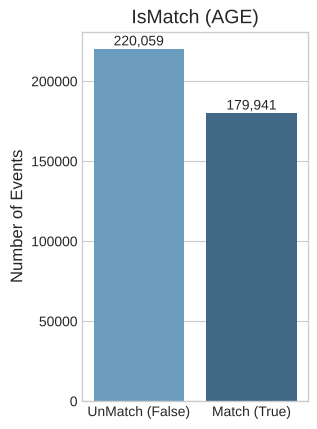

In [12]:
plt.subplot(1, 2, 1)
age_match_counts = df_final_analysis['IsMatch (AGE)'].value_counts()
age_match_counts.rename(index={True: 'Match (True)', False: 'UnMatch (False)'}, inplace=True)
sns.barplot(x=age_match_counts.index, y=age_match_counts.values, palette='Blues_d')
plt.title('IsMatch (AGE)', fontsize=14)
plt.ylabel('Number of Events', fontsize=12)
plt.xlabel('')
plt.xticks(rotation=0)
for index, value in enumerate(age_match_counts.values):
    plt.text(index, value + 500, f'{value:,}', ha='center', va='bottom', fontsize=10)

purchase_events = df_final_analysis[df_final_analysis['event_type'] == 'Purchase']
match_purchase_count = purchase_events['IsMatch (AGE)'].value_counts().get(True, 0)
total_match_count = df_final_analysis['IsMatch (AGE)'].value_counts().get(True, 0)
if total_match_count > 0:
    purchase_from_match_percentage = (match_purchase_count / total_match_count) * 100
else:
    purchase_from_match_percentage = 0
summary_data = {
    'Category': ['Match (True)', 'UnMatch (False)'],
    'Total Users': [df_final_analysis['IsMatch (AGE)'].value_counts().get(True, 0),
                    df_final_analysis['IsMatch (AGE)'].value_counts().get(False, 0)],
    'Purchase Users': [purchase_events['IsMatch (AGE)'].value_counts().get(True, 0),
                       purchase_events['IsMatch (AGE)'].value_counts().get(False, 0)]
}

df_summary = pd.DataFrame(summary_data)
df_summary['Purchase Percentage (%)'] = (df_summary['Purchase Users'] / df_summary['Total Users']) * 100
df_summary.set_index('Category', inplace=True)

print("\nPurchase Rates by Age Match Status:")
print(df_summary.to_markdown())

กราฟนี้โชว์ว่าโฆษณาที่ยิงไปและ user ที่มีส่วนร่วมกับ ads นั้นมีความ เข้ากันกับ targetของอายุ เท่าไหร่ และดูอีกว่าจำนวน user ถ้าเทียบกันว่าอัตราที่ user จากการซื้อนับเป็นกี่เปอร์เซ็นจากจำนวนทั้งหมดที่เห็นโฆษณา สังเกตุว่าโอกาสการซื้อแทบไม่ต่างกันเลย

--------------------------------------------------------------------------------
**Insight**

 **- ภาพรวมและประสิทธิภาพการซื้อ**

ผู้ใช้งานส่วนใหญ่ไม่ตรงกับความสนใจที่ตั้งไว้ UnMatch โดยมีจำนวนผู้ใช้งานที่ไม่ตรงกับความสนใจถึง 311,172 ราย เทียบกับผู้ใช้งานที่ตรงกับความสนใจ Match ที่มีเพียง 88,828 ราย

อัตราการซื้อใกล้เคียงกัน แม้ว่าจำนวนผู้ใช้งานจะแตกต่างกันอย่างมาก แต่อัตราการซื้อ  ของทั้งสองกลุ่มกลับไม่ต่างกันอย่างมีนัยสำคัญ โดยกลุ่ม Match  มีอัตราการซื้ออยู่ที่ 0.508849% และกลุ่ม UnMatch มีอัตราการซื้ออยู่ที่ 0.507436% ซึ่งแสดงให้เห็นว่าการตั้งค่าความสนใจยังไม่ได้ส่งผลต่อการตัดสินใจซื้ออย่างชัดเจน

**- การมีส่วนร่วมตามแพลตฟอร์ม**

user ที่ใช้ Facebook มีมากกว่า Instragram มากเกือบ 2 เท่า  , กลุ่มผู้ใช้งานที่มีการมีส่วนร่วมสูงสุดคือช่วงอายุ 18-24 ปี (108,082) และ 35-44 ปี (107,730) , โฆษณาประเภท Stories มีจำนวนการมีส่วนร่วมสูงสุด (128,238) ตามมาด้วยโฆษณาแบบ Image และ Carousel ซึ่งได้รับความนิยมใกล้เคียงกัน (103,803 และ 101,925 ตามลำดับ) ส่วนโฆษณาแบบ Video มีการมีส่วนร่วมต่ำที่สุด

**สรุป**

ข้อมูล IsMatch (AGE) แสดงให้เห็นว่าจำนวนผู้ใช้งานที่ไม่ตรงกับกลุ่มเป้าหมาย (UnMatch) มีมากกว่ากลุ่มที่ตรงเป้าหมาย (Match) อยู่เล็กน้อย โดยมีอัตราการซื้อของทั้งสองกลุ่มใกล้เคียงกัน

การที่ผู้ใช้งานส่วนใหญ่ไม่ตรงกับความสนใจที่ตั้งไว้ แต่กลับมีอัตราการซื้อที่ใกล้เคียงกันกับกลุ่มที่ตรงเป้าหมาย อาจเป็นสัญญาณว่าการกำหนดกลุ่มเป้าหมายด้วย ความสนใจ และ อายุ ยังไม่แม่นยำเท่าที่ควร หรืออาจมีปัจจัยอื่นนอกเหนือจากความสนใจที่ส่งผลต่อการซื้อมากกว่า

---------------------------------------------------------

Distribution of Ad Platforms for Matched vs. Unmatched Purchasers:
------------------------------------------------------------

--- Ad Platforms for Matched Purchasers ---
| ad_platform   |   proportion |
|:--------------|-------------:|
| Facebook      |      70.8155 |
| Instagram     |      29.1845 |

--- Ad Platforms for Unmatched Purchasers ---
| ad_platform   |   proportion |
|:--------------|-------------:|
| Facebook      |      60.3276 |
| Instagram     |      39.6724 |


<Figure size 1200x600 with 0 Axes>

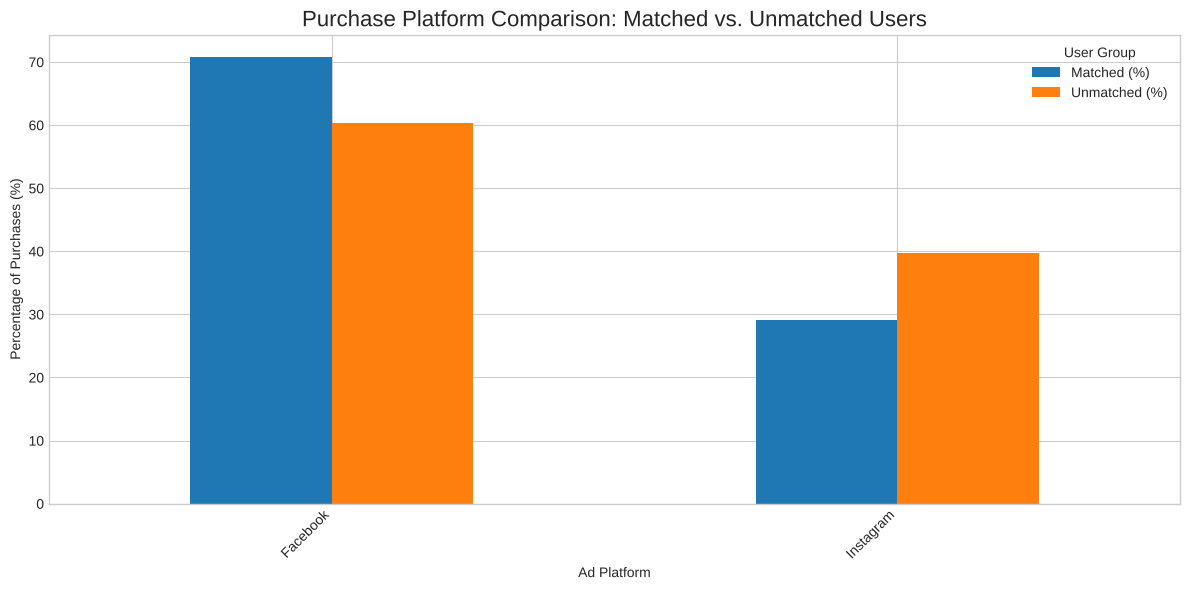

In [13]:
purchase_events = df_final_analysis[df_final_analysis['event_type'] == 'Purchase'].copy()
matched_purchasers = purchase_events[purchase_events['IsMatch (AGE)'] == True]
unmatched_purchasers = purchase_events[purchase_events['IsMatch (AGE)'] == False]

print("Distribution of Ad Platforms for Matched vs. Unmatched Purchasers:")
print("-" * 60)

print("\n--- Ad Platforms for Matched Purchasers ---")
matched_platform_counts = matched_purchasers['ad_platform'].value_counts(normalize=True).mul(100)
print(matched_platform_counts.to_markdown())

print("\n--- Ad Platforms for Unmatched Purchasers ---")
unmatched_platform_counts = unmatched_purchasers['ad_platform'].value_counts(normalize=True).mul(100)
print(unmatched_platform_counts.to_markdown())

platform_comparison = pd.concat([
    matched_platform_counts.rename('Matched (%)'),
    unmatched_platform_counts.rename('Unmatched (%)')
], axis=1).fillna(0).sort_index()

plt.figure(figsize=(12, 6))
platform_comparison.plot(kind='bar', figsize=(12, 6))
plt.title('Purchase Platform Comparison: Matched vs. Unmatched Users', fontsize=16)
plt.xlabel('Ad Platform')
plt.ylabel('Percentage of Purchases (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='User Group')
plt.tight_layout()
plt.show()

เมื่อมาดูลึกเกี่ยวกับว่า user ที่ Purchase มีอะไรเหมือนกันนั้น ดูจาก Percent และ User ที่ใช้ Platform จาก Facebook สูงกว่า IG เปอร์เซ็นการซื้อของ Facebook อยู่ที่ 60% และ IG อยู่ที่ 39%

---------------------------------------------------------



Distribution of Ad Types for Matched vs. Unmatched Purchasers:
------------------------------------------------------------

--- Ad Types for Matched Purchasers ---
| ad_type   |   proportion |
|:----------|-------------:|
| Stories   |      32.4034 |
| Image     |      26.824  |
| Carousel  |      21.7811 |
| Video     |      18.9914 |

--- Ad Types for Unmatched Purchasers ---
| ad_type   |   proportion |
|:----------|-------------:|
| Stories   |      34.6679 |
| Carousel  |      28.9354 |
| Image     |      21.747  |
| Video     |      14.6497 |


<Figure size 1200x600 with 0 Axes>

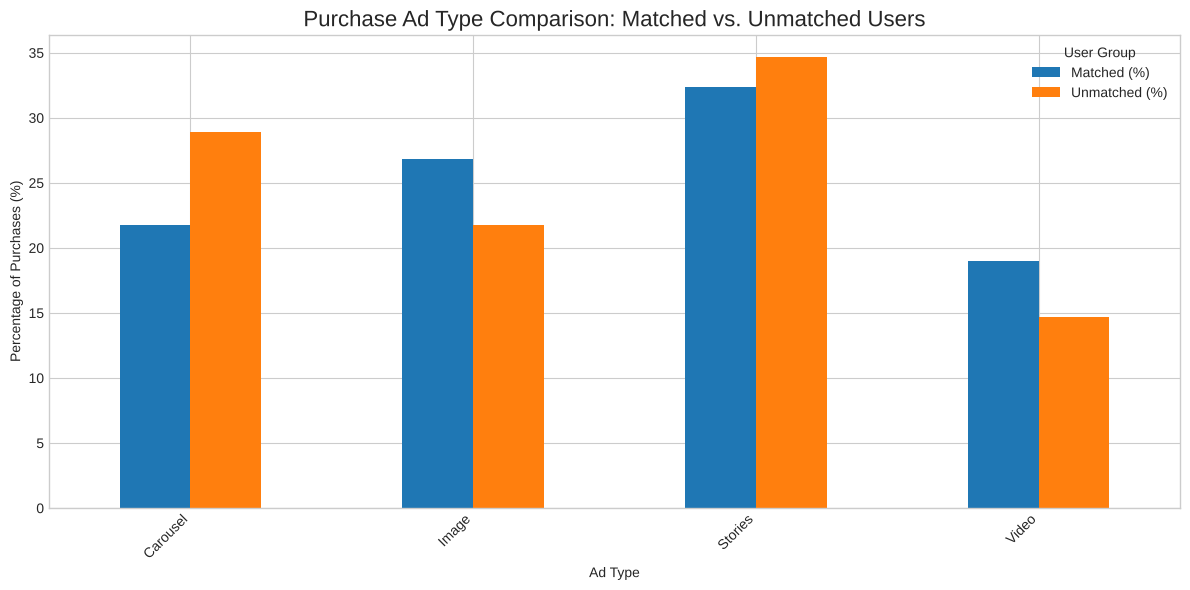

In [14]:
print("\n\nDistribution of Ad Types for Matched vs. Unmatched Purchasers:")
print("-" * 60)
print("\n--- Ad Types for Matched Purchasers ---")
matched_ad_type_counts = matched_purchasers['ad_type'].value_counts(normalize=True).mul(100)
print(matched_ad_type_counts.to_markdown())

print("\n--- Ad Types for Unmatched Purchasers ---")
unmatched_ad_type_counts = unmatched_purchasers['ad_type'].value_counts(normalize=True).mul(100)
print(unmatched_ad_type_counts.to_markdown())

ad_type_comparison = pd.concat([
    matched_ad_type_counts.rename('Matched (%)'),
    unmatched_ad_type_counts.rename('Unmatched (%)')
], axis=1).fillna(0).sort_index()

plt.figure(figsize=(12, 6))
ad_type_comparison.plot(kind='bar', figsize=(12, 6))
plt.title('Purchase Ad Type Comparison: Matched vs. Unmatched Users', fontsize=16)
plt.xlabel('Ad Type')
plt.ylabel('Percentage of Purchases (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='User Group')
plt.tight_layout()
plt.show()

และมาเจาะดูอีกว่าอะไรที่เหมือนกันอีกสุงเกตุว่าเปอร์เซ็นที่ User จะซื้อที่สุดคือ Stories

----------------------------------------------------------------------------

<Figure size 1200x800 with 0 Axes>

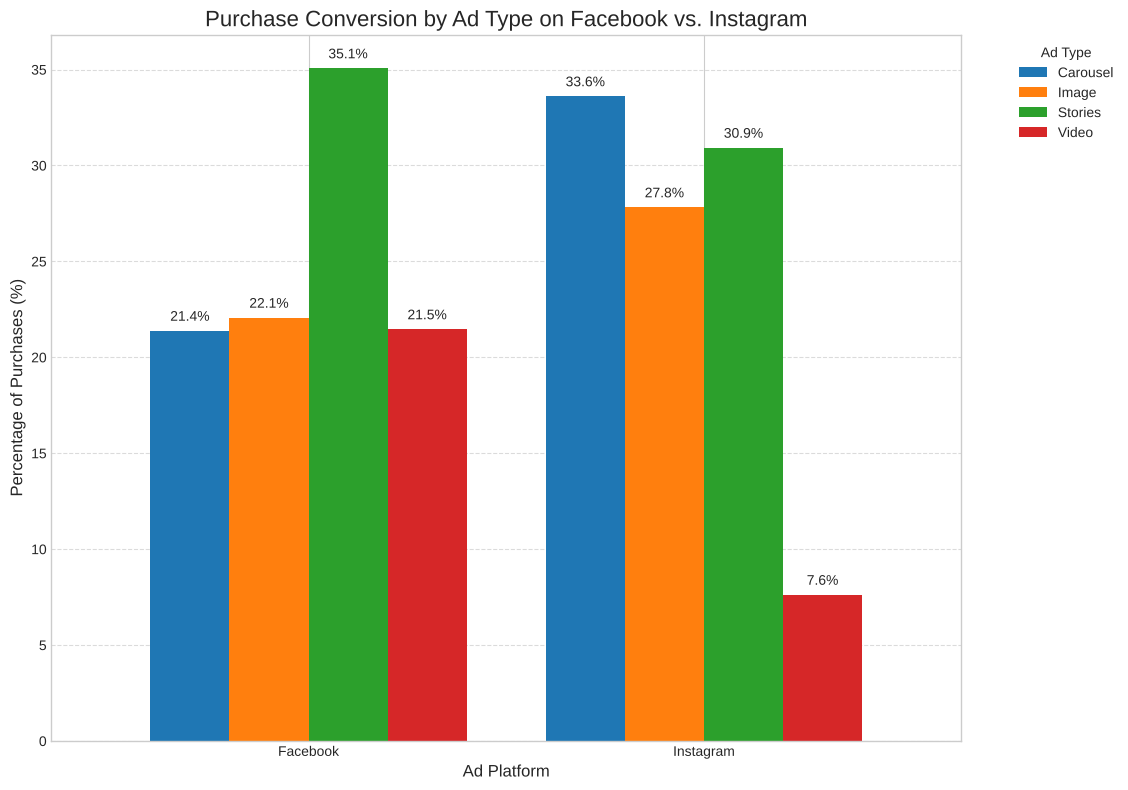


Purchase Conversion Data Table:
| ad_platform   |   Carousel |   Image |   Stories |    Video |
|:--------------|-----------:|--------:|----------:|---------:|
| Facebook      |    21.3908 | 22.0711 |   35.0718 | 21.4664  |
| Instagram     |    33.6158 | 27.8249 |   30.9322 |  7.62712 |


In [15]:
purchase_events = df_final_analysis[df_final_analysis['event_type'] == 'Purchase'].copy()

fb_ig_purchases = purchase_events[
    purchase_events['ad_platform'].isin(['Facebook', 'Instagram'])
]

ad_type_by_platform = fb_ig_purchases.groupby('ad_platform')['ad_type'].value_counts(normalize=True).mul(100).unstack(fill_value=0)

plt.figure(figsize=(12, 8))
ad_type_by_platform.plot(kind='bar', figsize=(12, 8), width=0.8)

plt.title('Purchase Conversion by Ad Type on Facebook vs. Instagram', fontsize=16)
plt.xlabel('Ad Platform', fontsize=12)
plt.ylabel('Percentage of Purchases (%)', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Ad Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.1f%%', label_type='edge', fontsize=10, padding=5)

plt.tight_layout(rect=[0, 0, 0.95, 1])
plt.show()
print("\nPurchase Conversion Data Table:")
print(ad_type_by_platform.to_markdown())

กราฟโชว์ถึงระหว่าง platform สังเกตุว่า โอกาสที่จะมีการ Purchase สูงที่สุดของ Facebook คือ Stories ที่สูงถึง 35% ส่วน ของ Instagram จะเป็น Carousel ที่สูงถึง 33% และ Stories อยู่ที่ 30.9%

 **สรุป**

จากกราฟทั้งหมดจะโชว์ให้เห็นได้ว่าการยิง ads ไปที่กลุ่ม target และเกิดการมีส่วนร่วมของ user นั้น target ทางด้านความสนใจและอายุไม่ได้ส่งผลต่อการซื้อของ user แต่สิ่งที่ทำให้ user สนใจในตัวของ ads นั้นจะเป็นประเภทของ ads และ platform ต่างหาก โดยกราฟแสดงให้เห็นว่าประเภทโฆษณาที่ดีที่สุดคือ stories และ video เป็นตัวเลือกที่แย่ที่สุด หากเราต้องการเพิ่มยอดขายโดยการลด budget ads ลงให้เราทำการโฆษณาโดยใช้ stories และโฆษณาผ่าน 2 platform จะทำให้โอกาสขายออกสูงที่สุดตัวเลือกประเภทโฆษณาเดี่ยว

หากจะยิง ads ครั้งต่อไปควรเลือก platform ที่เหมาะสมและ รูปแบบโฆษณาที่ถูกต้อง

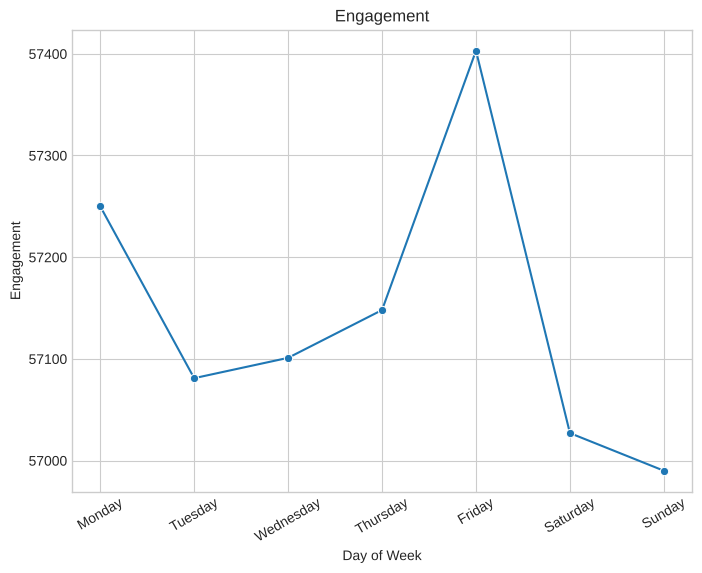

In [16]:
#Plot กราฟดูว่าหนึ่งในอาทิตย์มี Engagement เท่าไหร่ในแต่ละวัน เพื่อดูว่าวันไหนมี Engagement มากที่สุด
day_count = ad_events_df.groupby("day_of_week").size().reset_index(name="count")

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_count["day_of_week"] = pd.Categorical(day_count["day_of_week"], categories=day_order, ordered=True)
day_count = day_count.sort_values("day_of_week")

# plt.figure(figsize=(8,6))
# ax = sns.barplot(data=day_count, x="day_of_week", y="count", color="skyblue")

# for p in ax.patches:
#     ax.annotate(f'{p.get_height():,.0f}',
#                 (p.get_x() + p.get_width() / 2., p.get_height()),
#                 ha='center', va='bottom', fontsize=10, color='black', rotation=0)

# plt.title("Engagement")
# plt.xlabel("Day of Week")
# plt.ylabel("Engagement")
# plt.xticks(rotation=30)

plt.figure(figsize=(8,6))
sns.lineplot(data=day_count, x="day_of_week", y="count", marker="o")
plt.title("Engagement")
plt.xlabel("Day of Week")
plt.ylabel("Engagement")
plt.xticks(rotation=30)
plt.show()

In [17]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
df_merged_prep = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')

# Feature Engineering: Extracting Hour of Day (REQUIRED for plotting)
df_merged_prep['timestamp'] = pd.to_datetime(df_merged_prep['timestamp'])
df_merged_prep['hour_of_day'] = df_merged_prep['timestamp'].dt.hour

# Monday

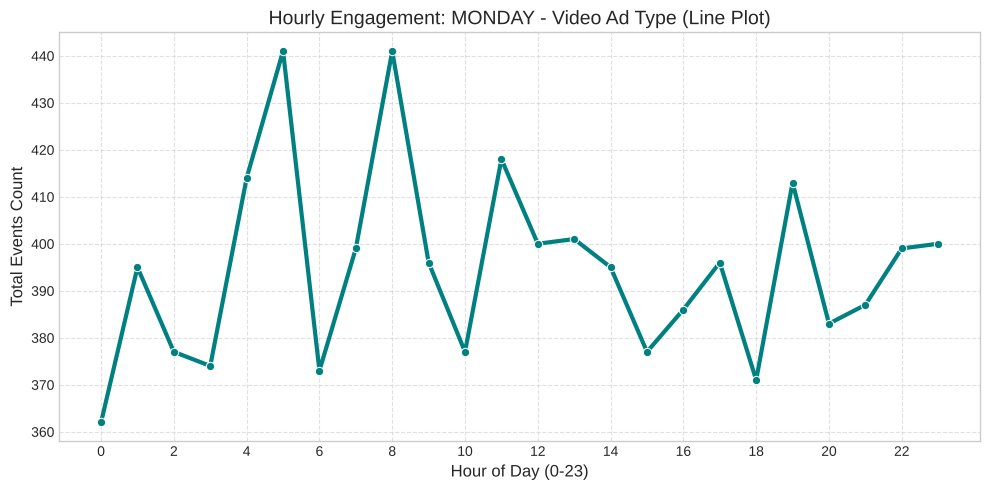

In [18]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Monday') &
    (df_merged_prep['ad_type'] == 'Video')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: MONDAY - Video Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

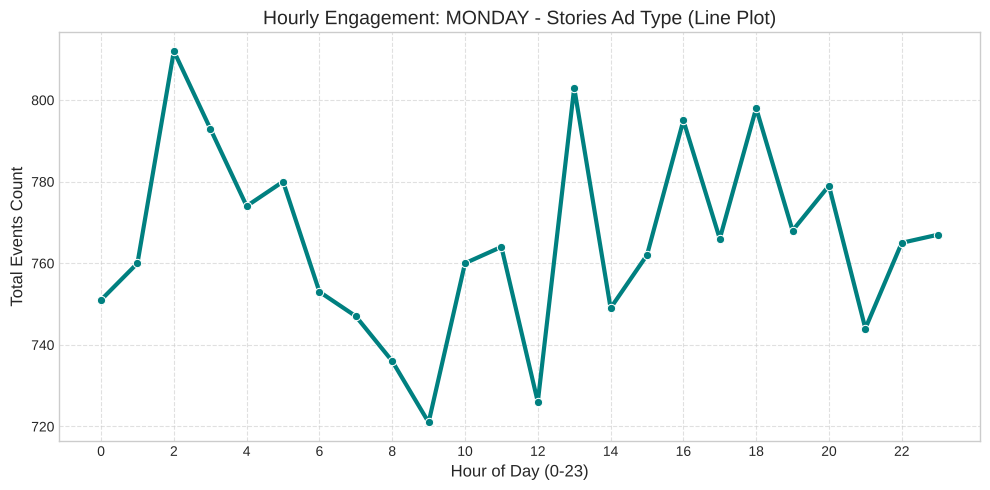

In [19]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Monday') &
    (df_merged_prep['ad_type'] == 'Stories')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: MONDAY - Stories Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

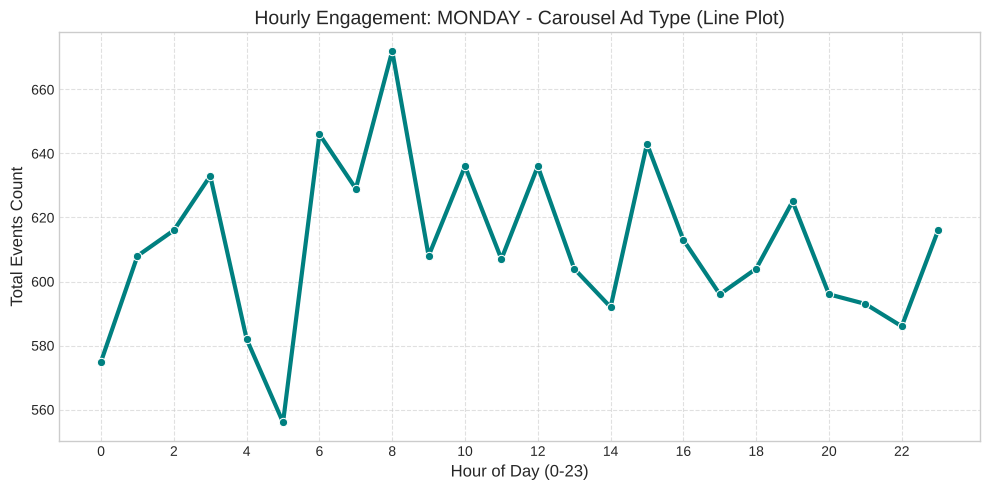

In [20]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Monday') &
    (df_merged_prep['ad_type'] == 'Carousel')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: MONDAY - Carousel Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

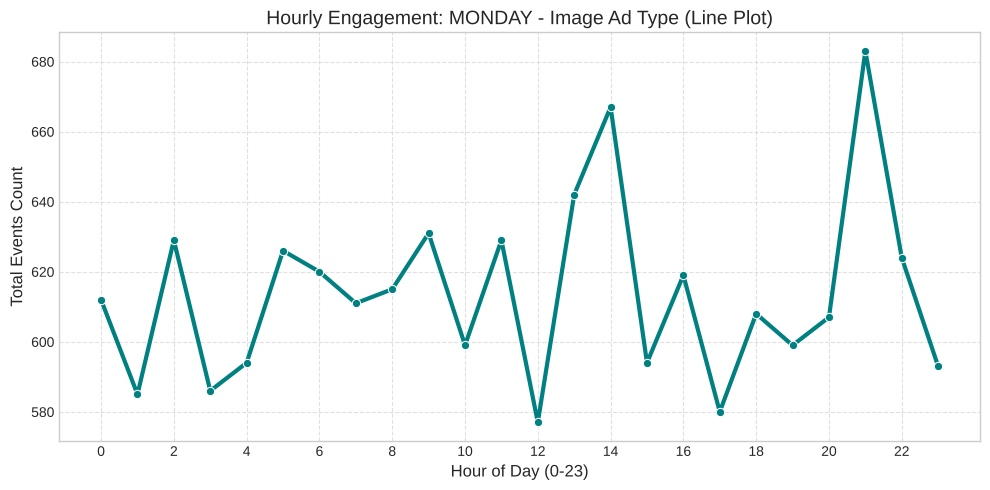

In [21]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Monday') &
    (df_merged_prep['ad_type'] == 'Image')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: MONDAY - Image Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

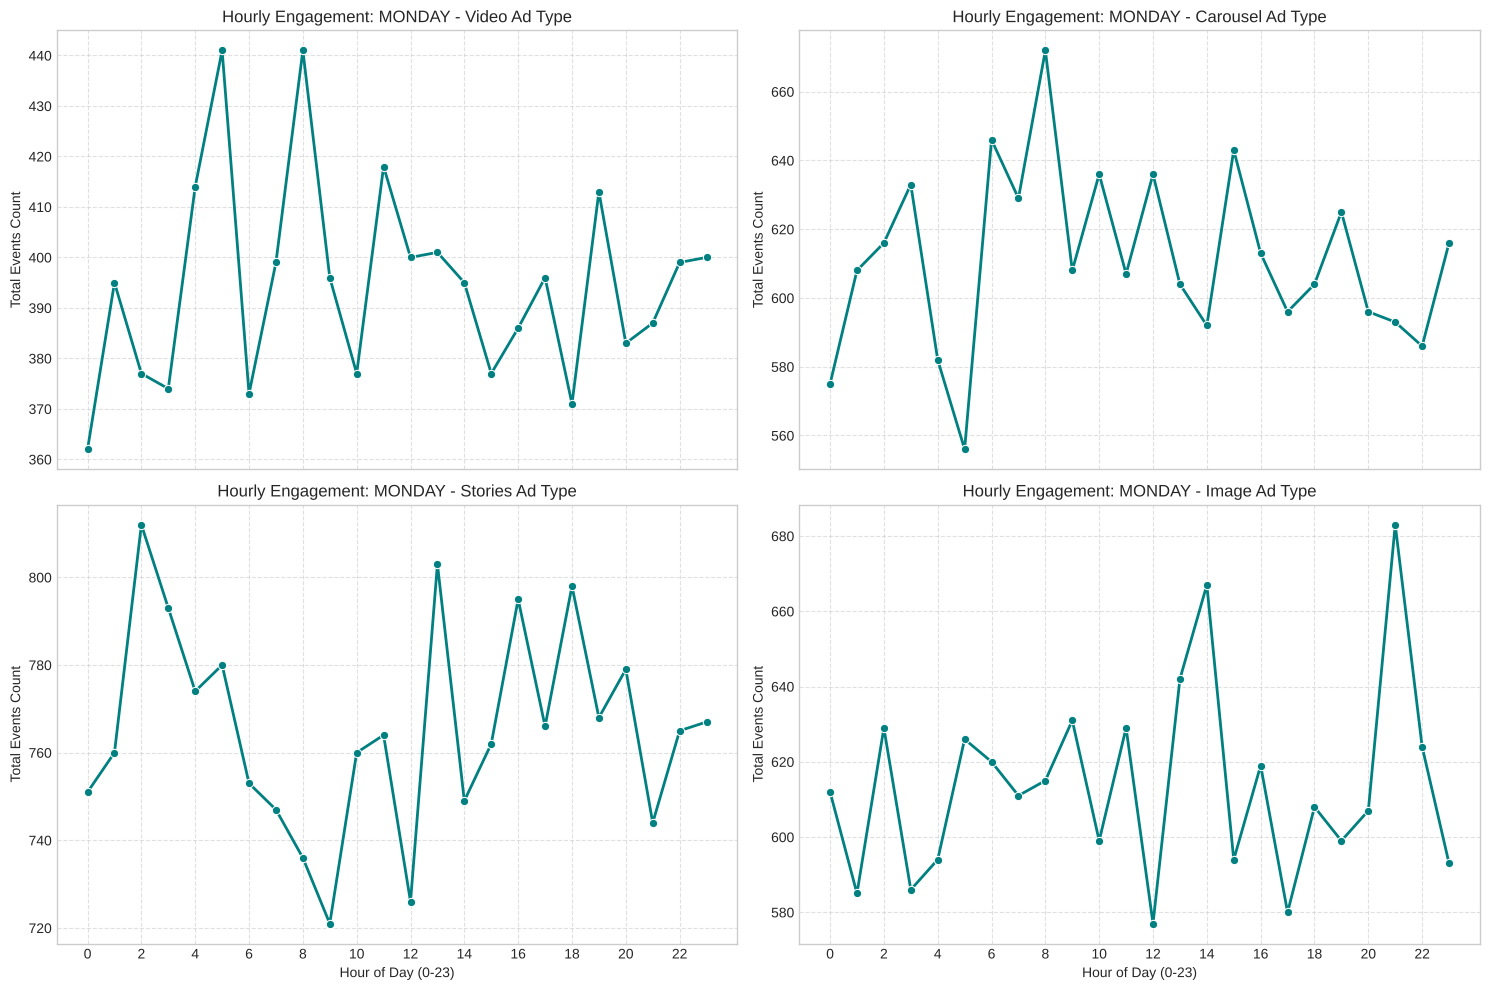

In [22]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == 'Monday') &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color='teal',
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: MONDAY - {title}", fontsize=12)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Tuesday

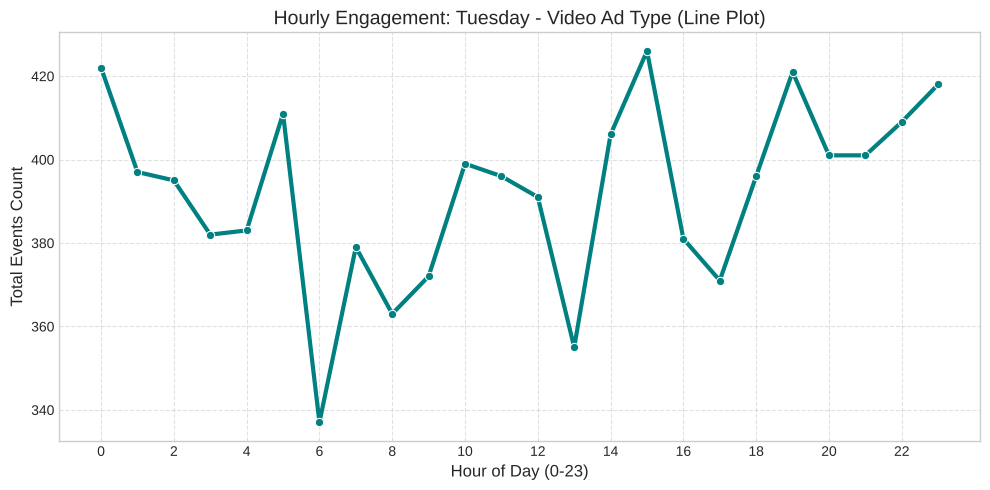

In [23]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Tuesday') &
    (df_merged_prep['ad_type'] == 'Video')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Tuesday - Video Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

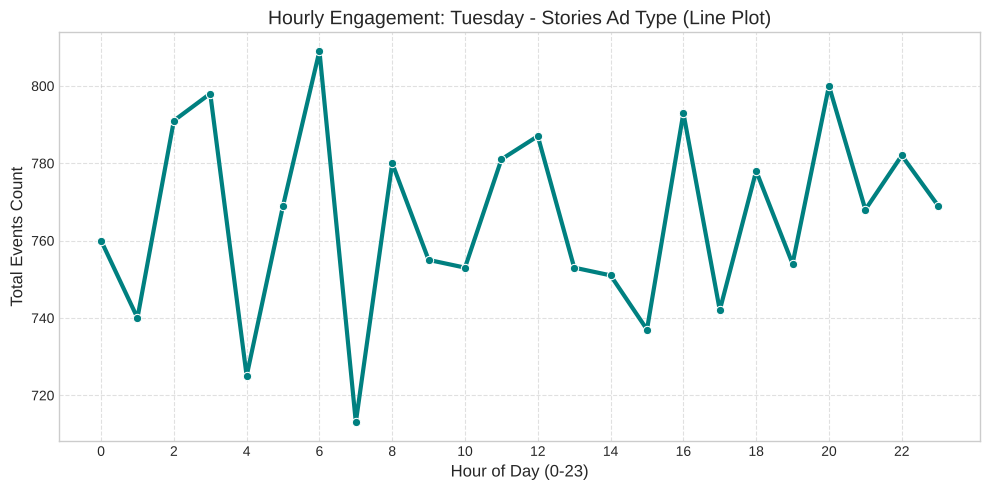

In [24]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Tuesday') &
    (df_merged_prep['ad_type'] == 'Stories')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Tuesday - Stories Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

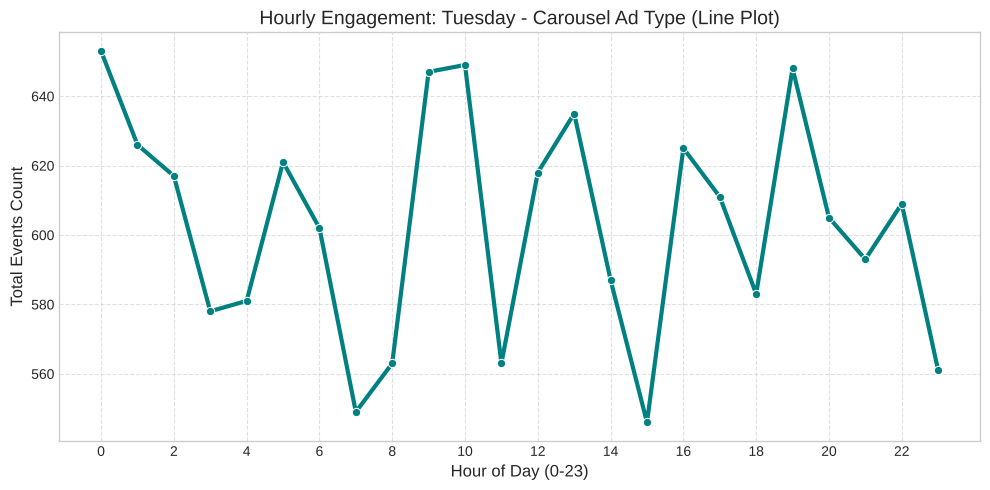

In [25]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Tuesday') &
    (df_merged_prep['ad_type'] == 'Carousel')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Tuesday - Carousel Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

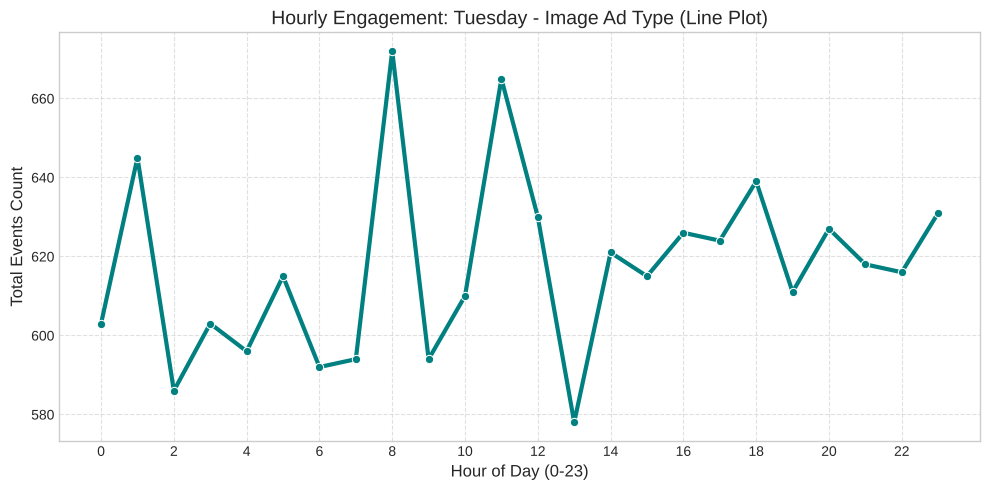

In [26]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Tuesday') &
    (df_merged_prep['ad_type'] == 'Image')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Tuesday - Image Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

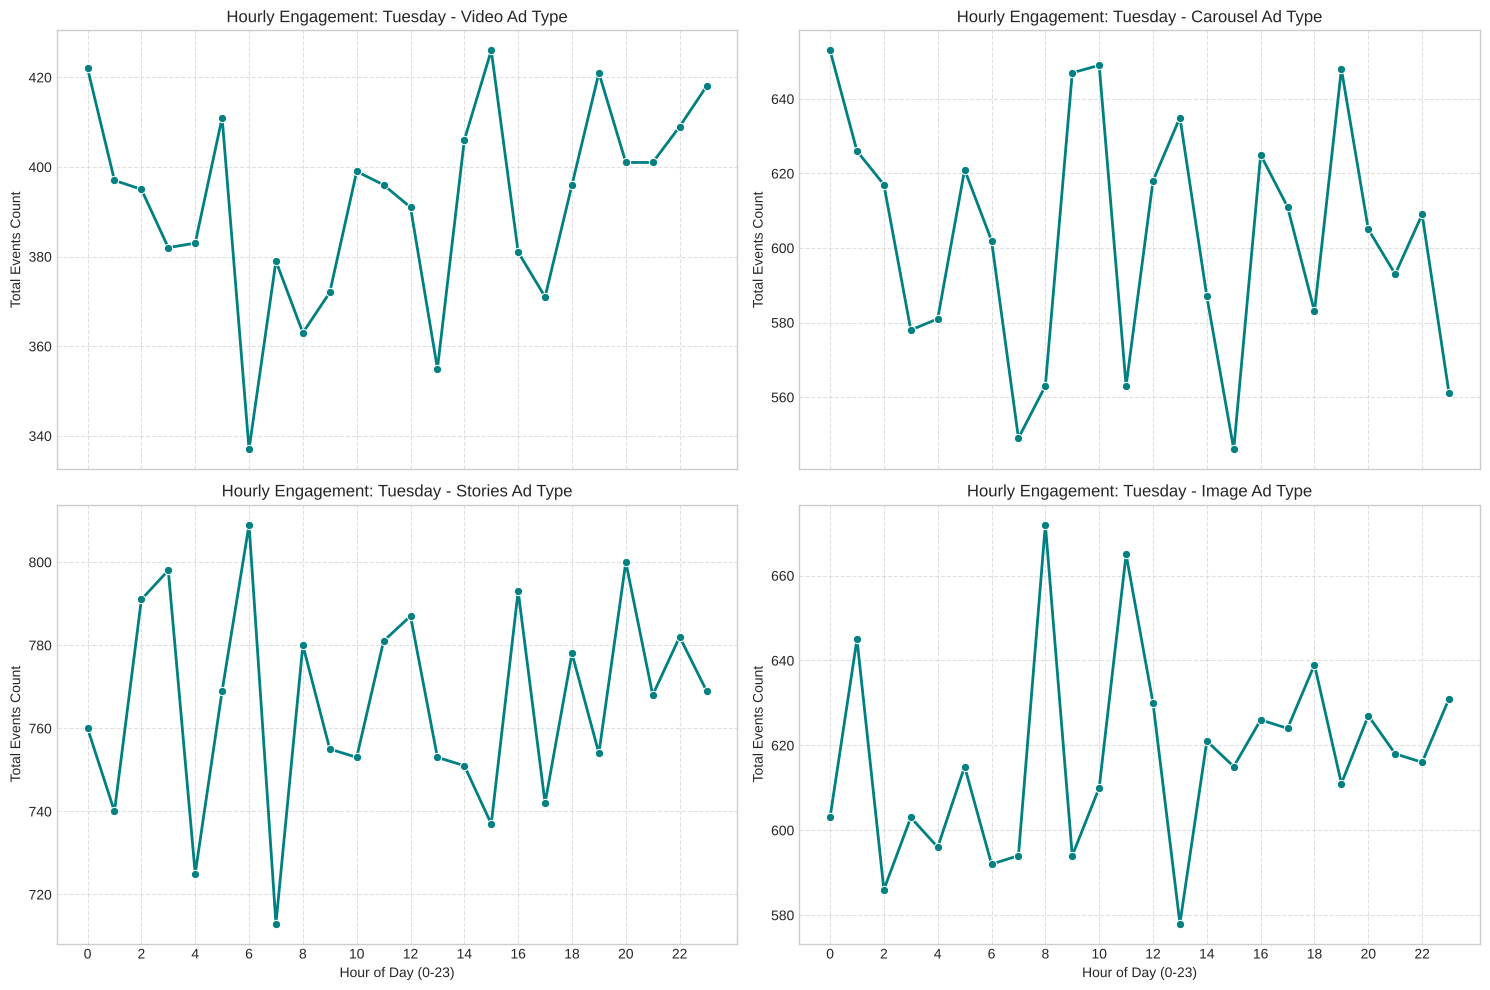

In [27]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == 'Tuesday') &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color='teal',
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: Tuesday - {title}", fontsize=12)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#Wednesday

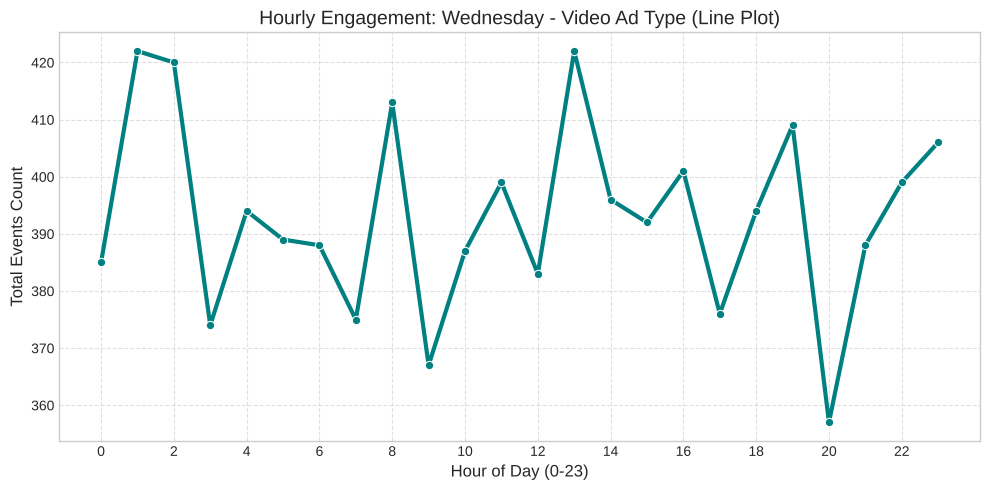

In [28]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Wednesday') &
    (df_merged_prep['ad_type'] == 'Video')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Wednesday - Video Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

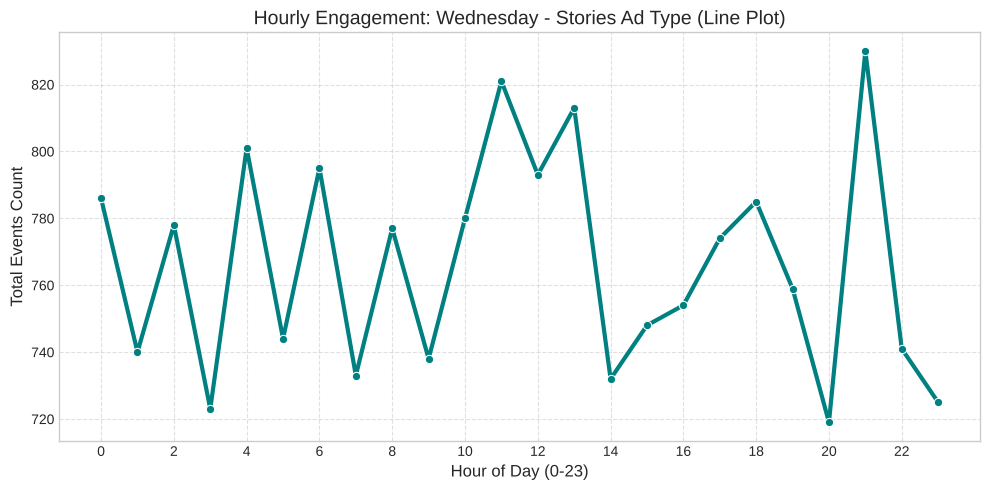

In [29]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Wednesday') &
    (df_merged_prep['ad_type'] == 'Stories')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Wednesday - Stories Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

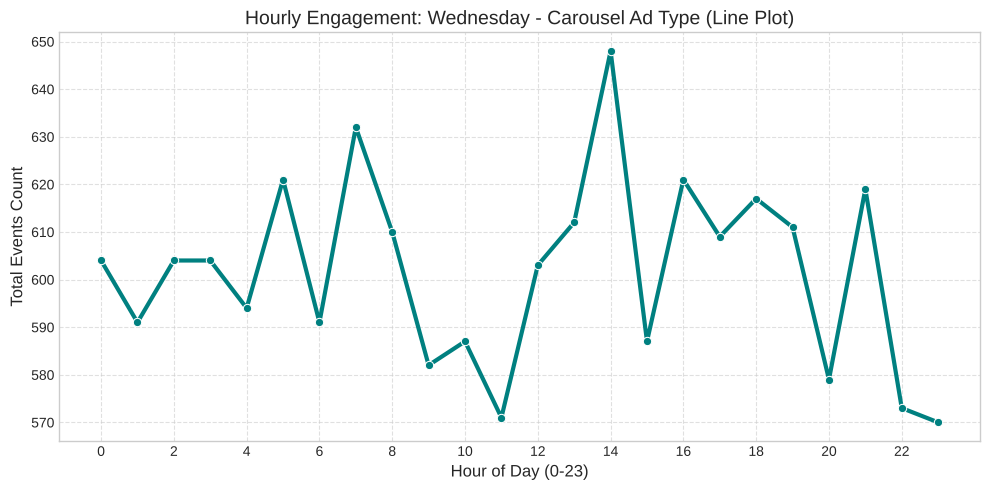

In [30]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Wednesday') &
    (df_merged_prep['ad_type'] == 'Carousel')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Wednesday - Carousel Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

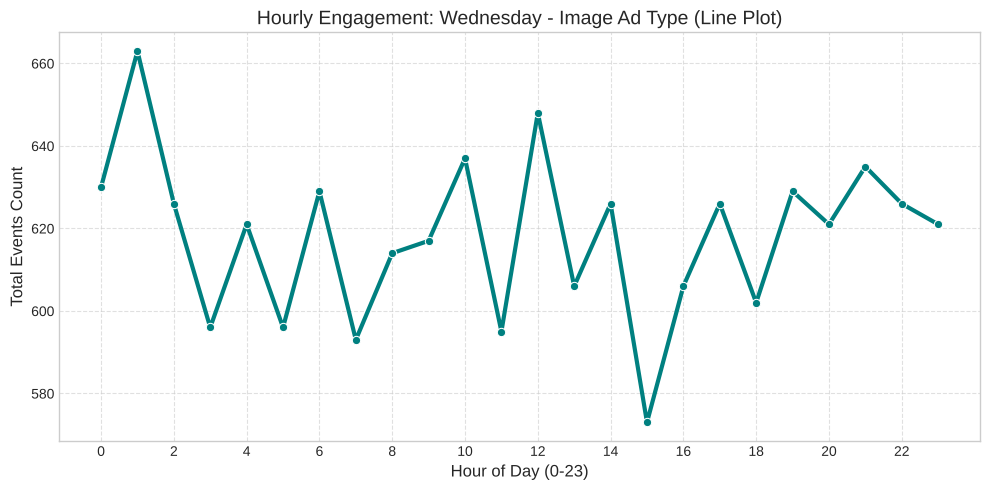

In [31]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Wednesday') &
    (df_merged_prep['ad_type'] == 'Image')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Wednesday - Image Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

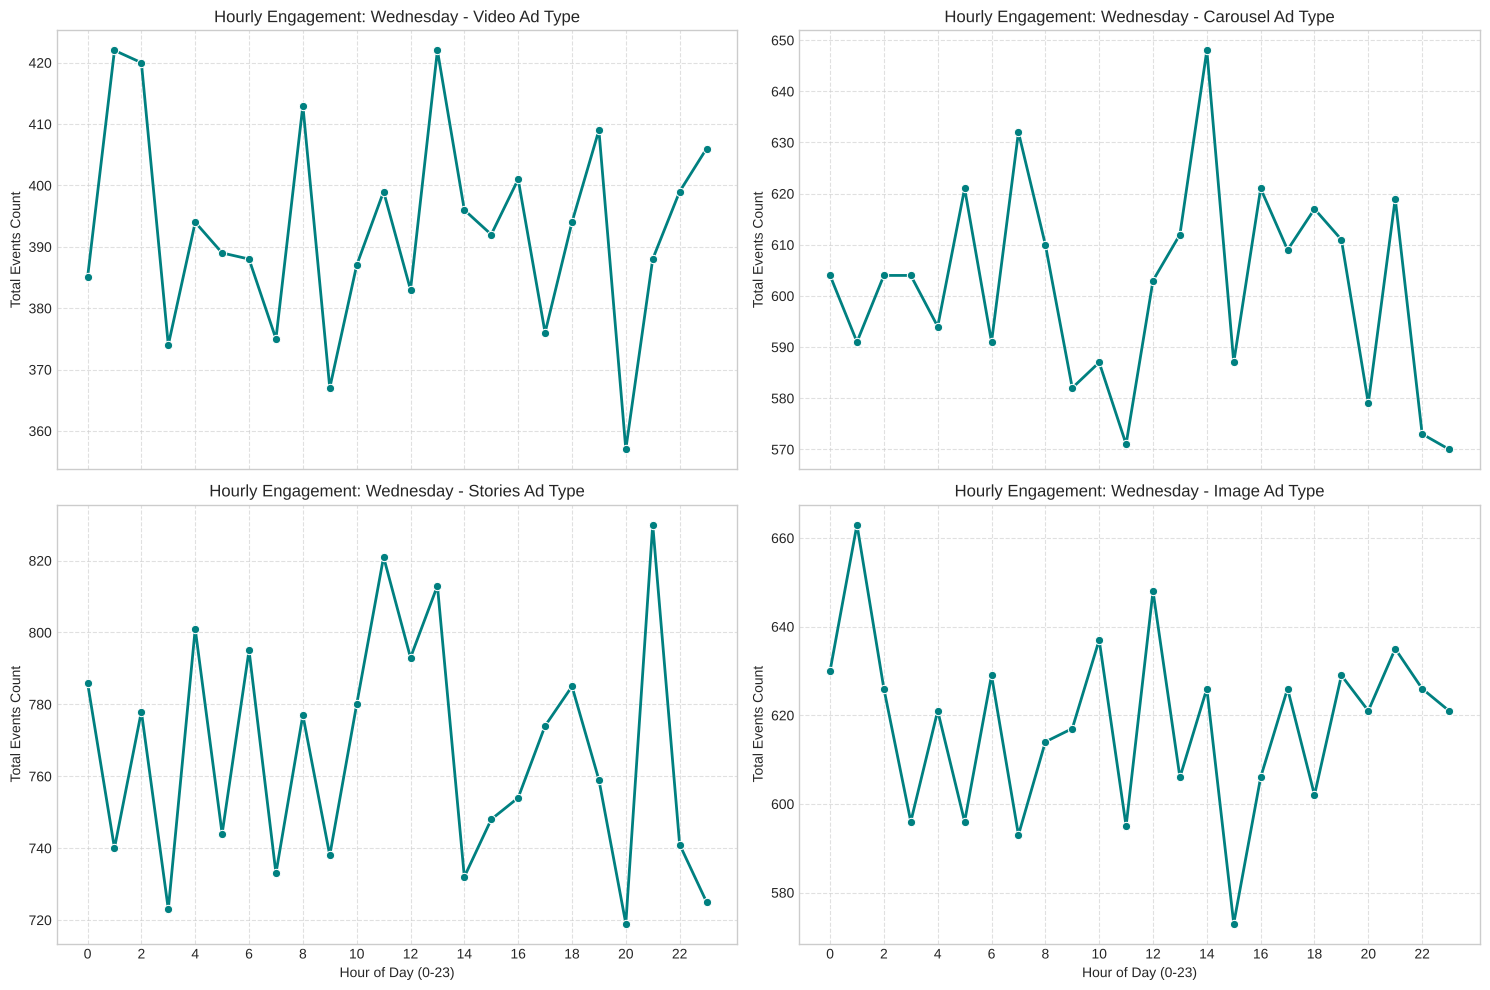

In [32]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == 'Wednesday') &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color='teal',
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: Wednesday - {title}", fontsize=12)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Thursday

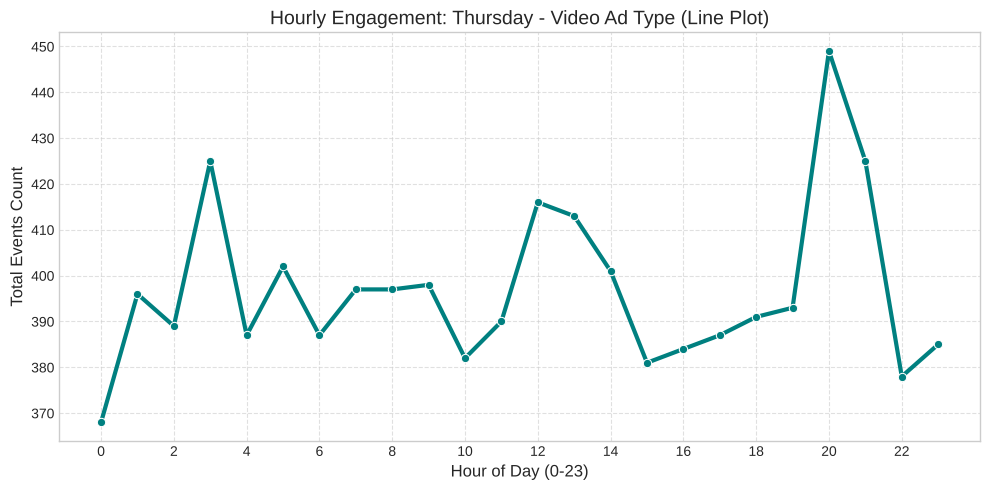

In [33]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Thursday') &
    (df_merged_prep['ad_type'] == 'Video')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Thursday - Video Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

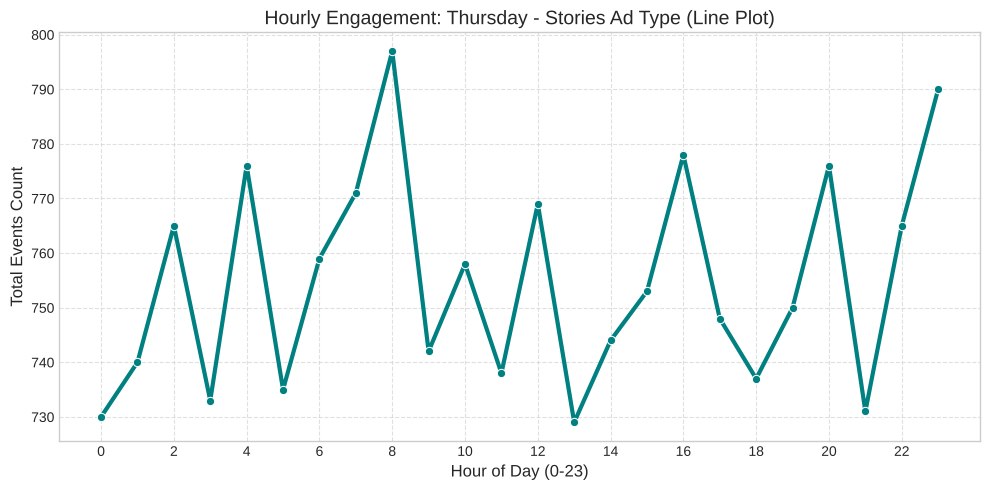

In [34]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Thursday') &
    (df_merged_prep['ad_type'] == 'Stories')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Thursday - Stories Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

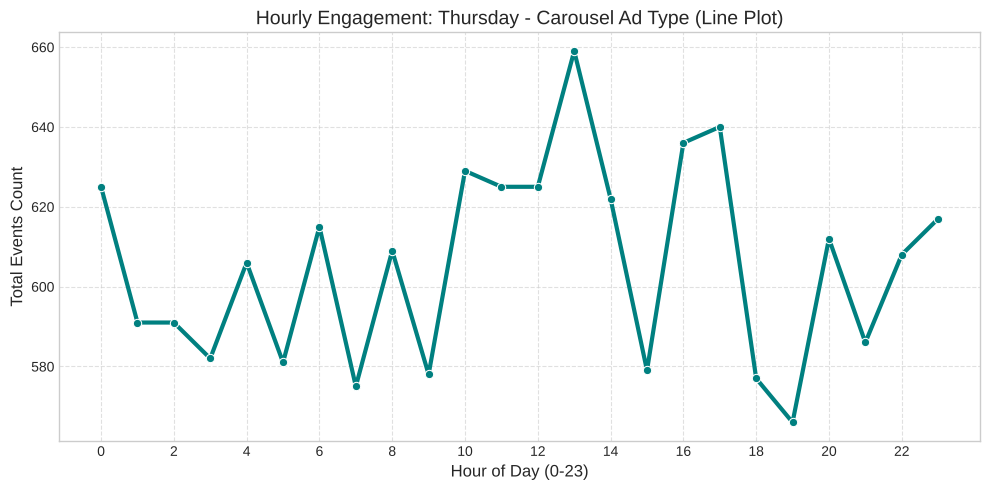

In [35]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Thursday') &
    (df_merged_prep['ad_type'] == 'Carousel')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Thursday - Carousel Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

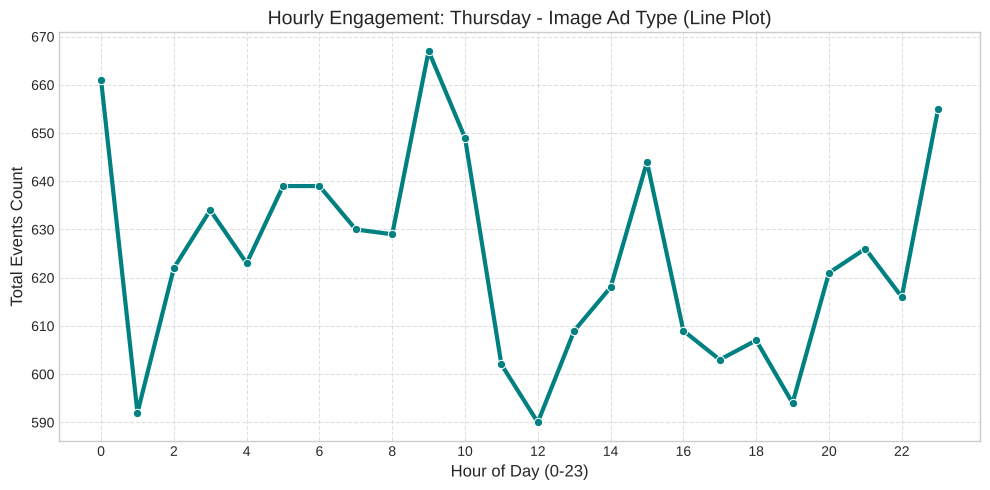

In [36]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Thursday') &
    (df_merged_prep['ad_type'] == 'Image')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Thursday - Image Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

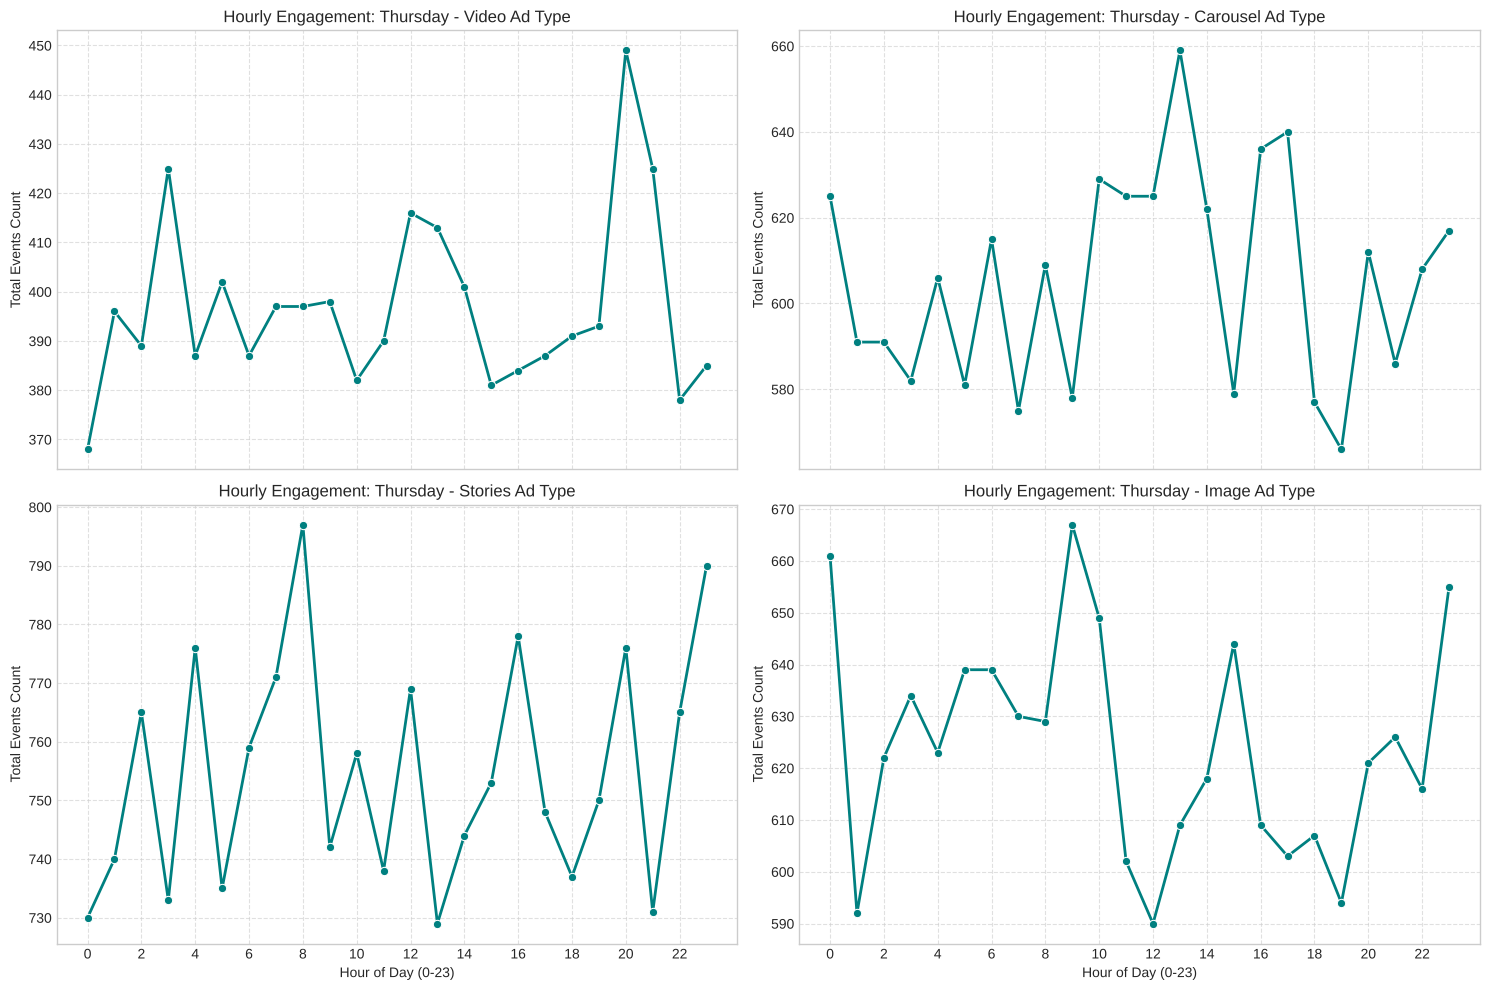

In [37]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == 'Thursday') &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color='teal',
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: Thursday - {title}", fontsize=12)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#Friday


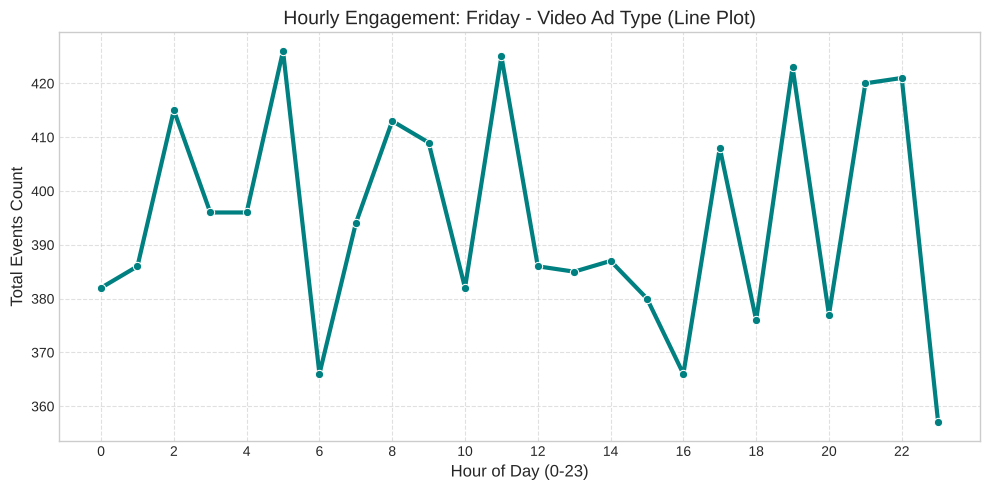

In [38]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Friday') &
    (df_merged_prep['ad_type'] == 'Video')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Friday - Video Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

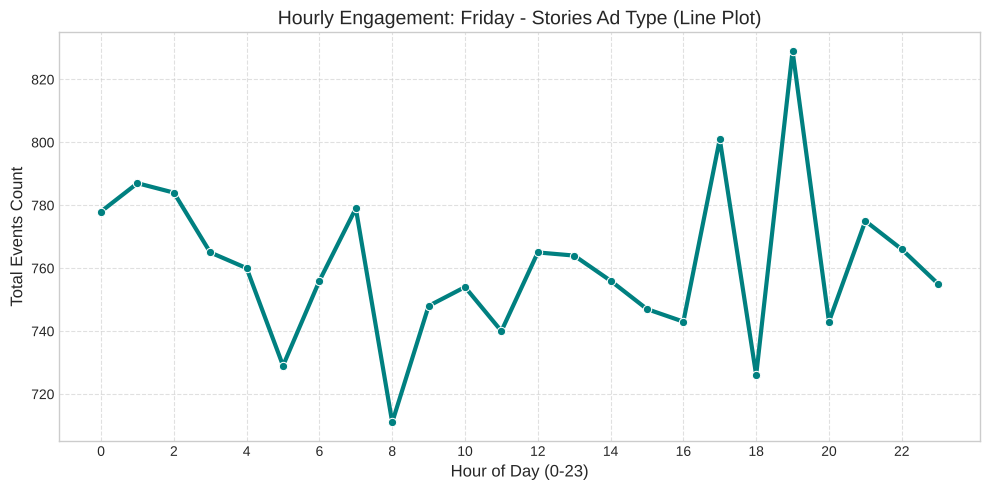

In [39]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Friday') &
    (df_merged_prep['ad_type'] == 'Stories')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Friday - Stories Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

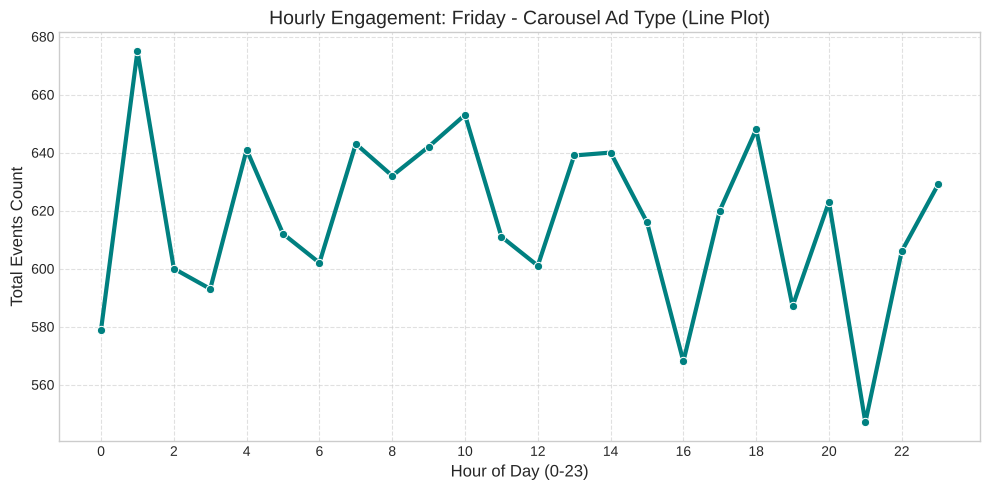

In [40]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Friday') &
    (df_merged_prep['ad_type'] == 'Carousel')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Friday - Carousel Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

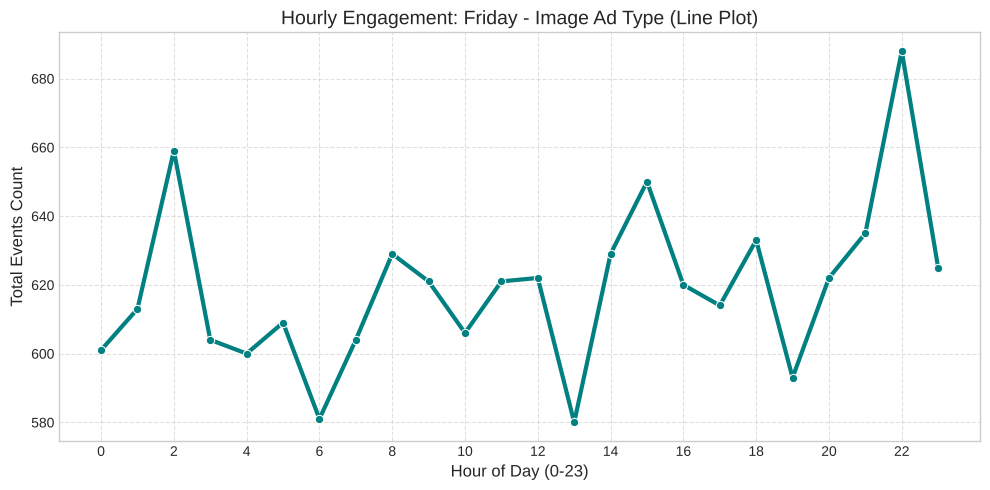

In [41]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Friday') &
    (df_merged_prep['ad_type'] == 'Image')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Friday - Image Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

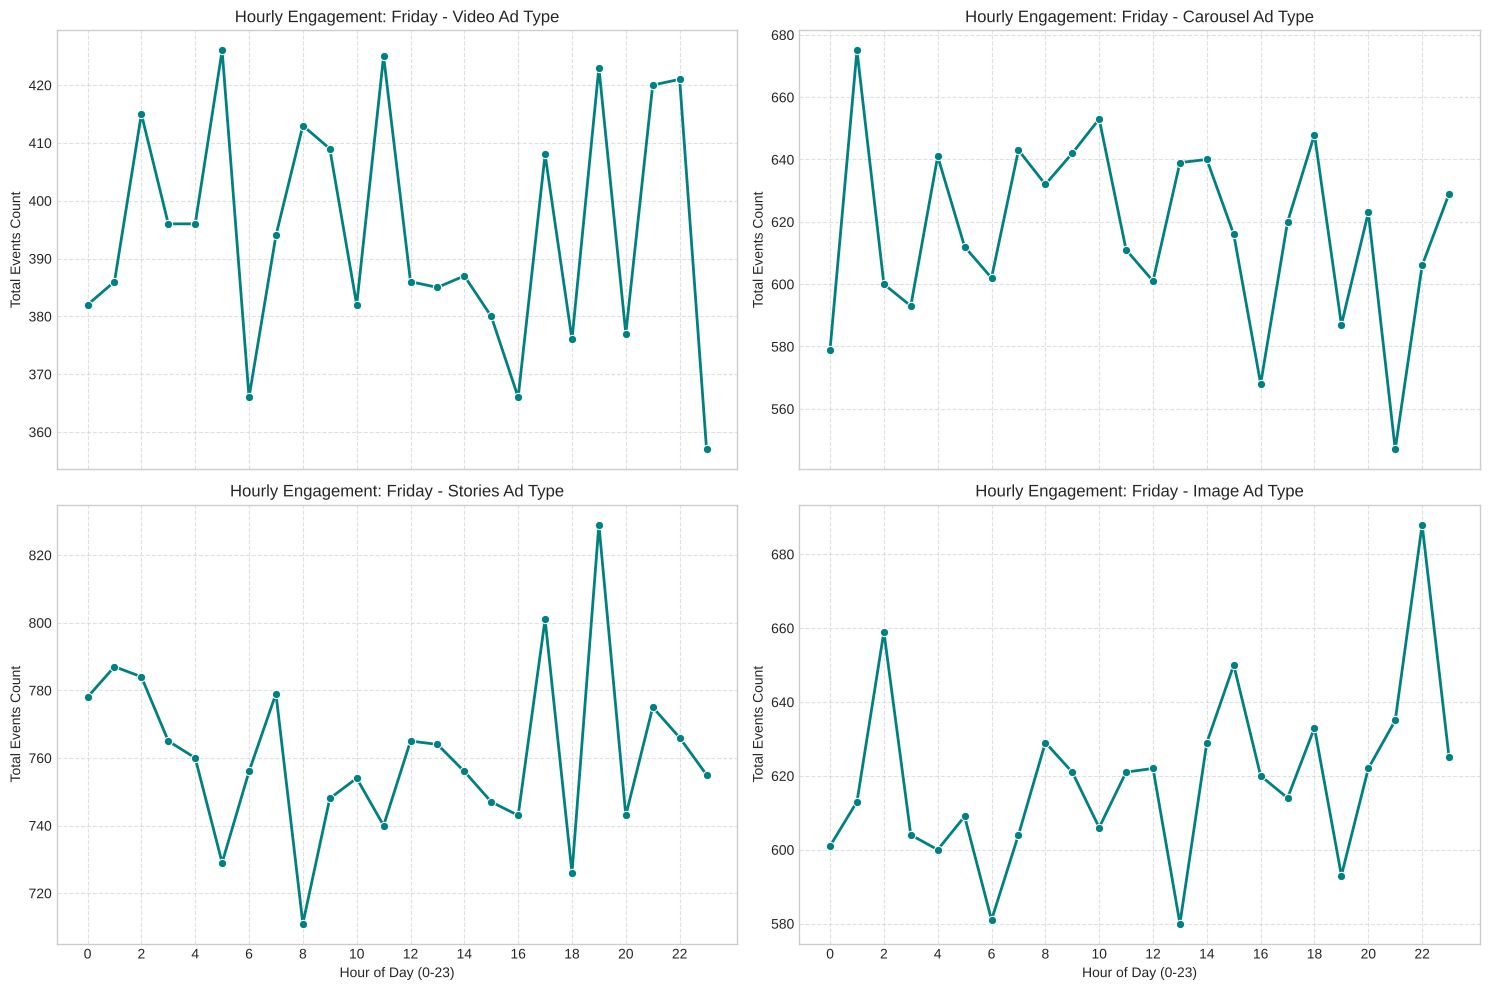

In [42]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == 'Friday') &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color='teal',
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: Friday - {title}", fontsize=12)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Saturday

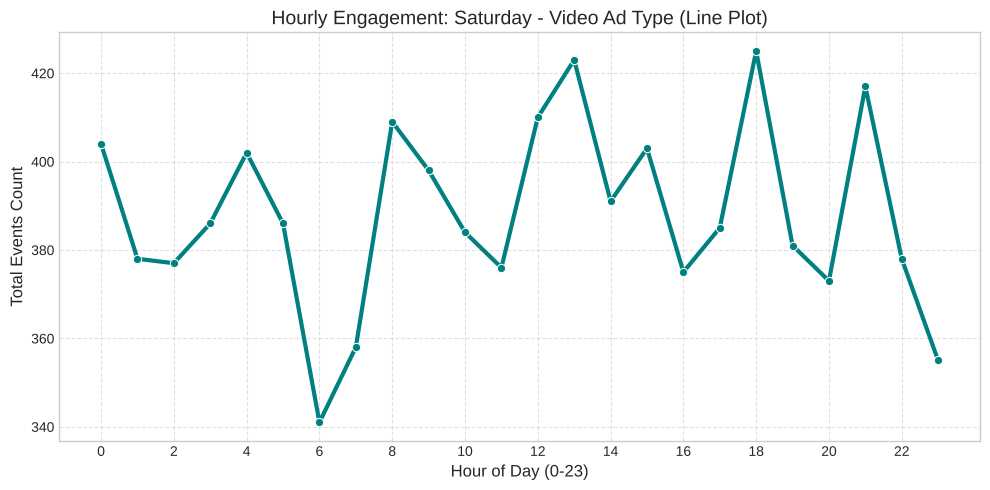

In [43]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Saturday') &
    (df_merged_prep['ad_type'] == 'Video')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Saturday - Video Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

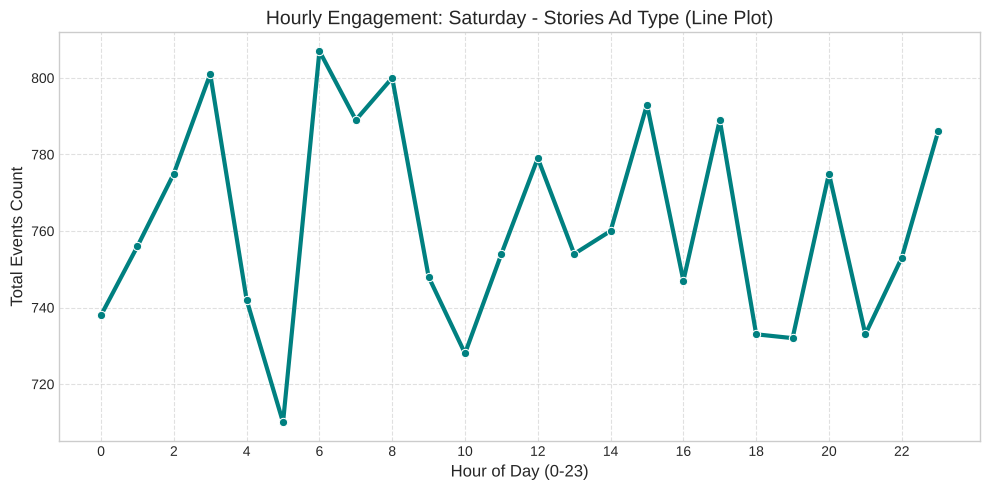

In [44]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Saturday') &
    (df_merged_prep['ad_type'] == 'Stories')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Saturday - Stories Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

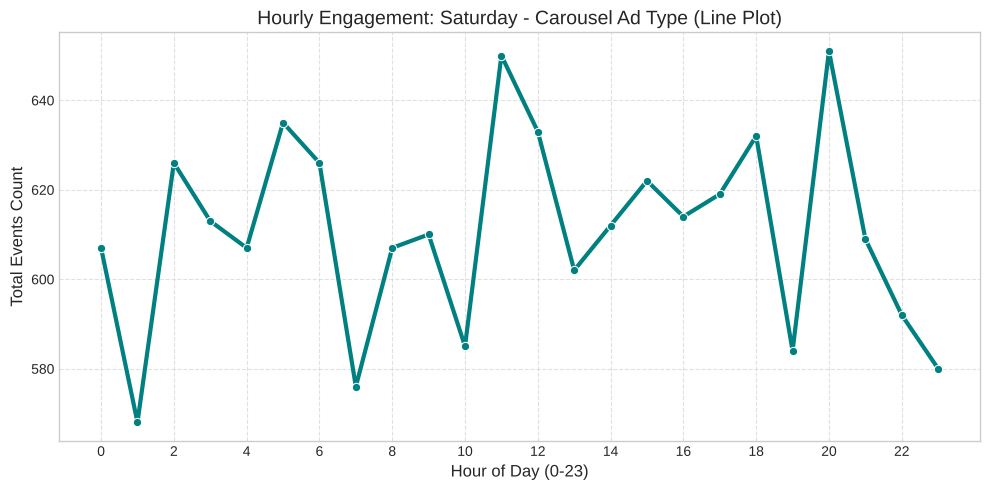

In [45]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Saturday') &
    (df_merged_prep['ad_type'] == 'Carousel')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Saturday - Carousel Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

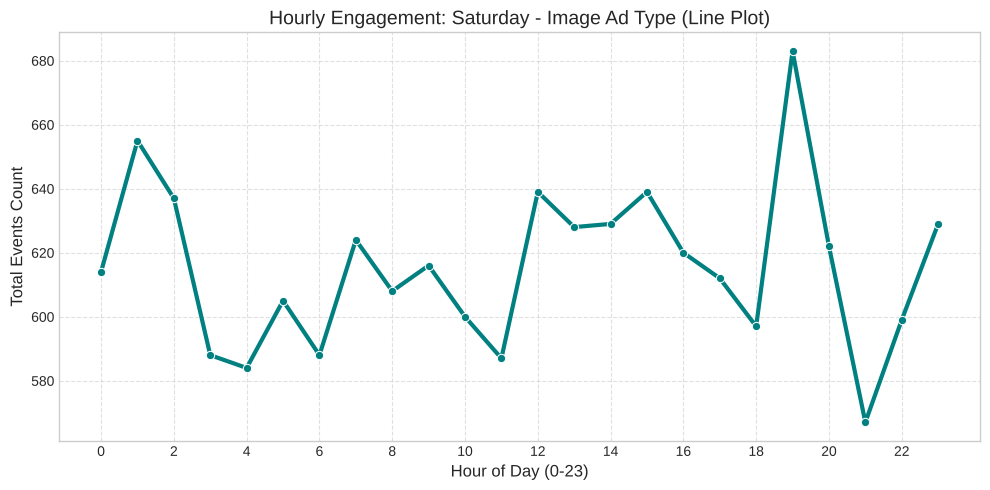

In [46]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Saturday') &
    (df_merged_prep['ad_type'] == 'Image')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Saturday - Image Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

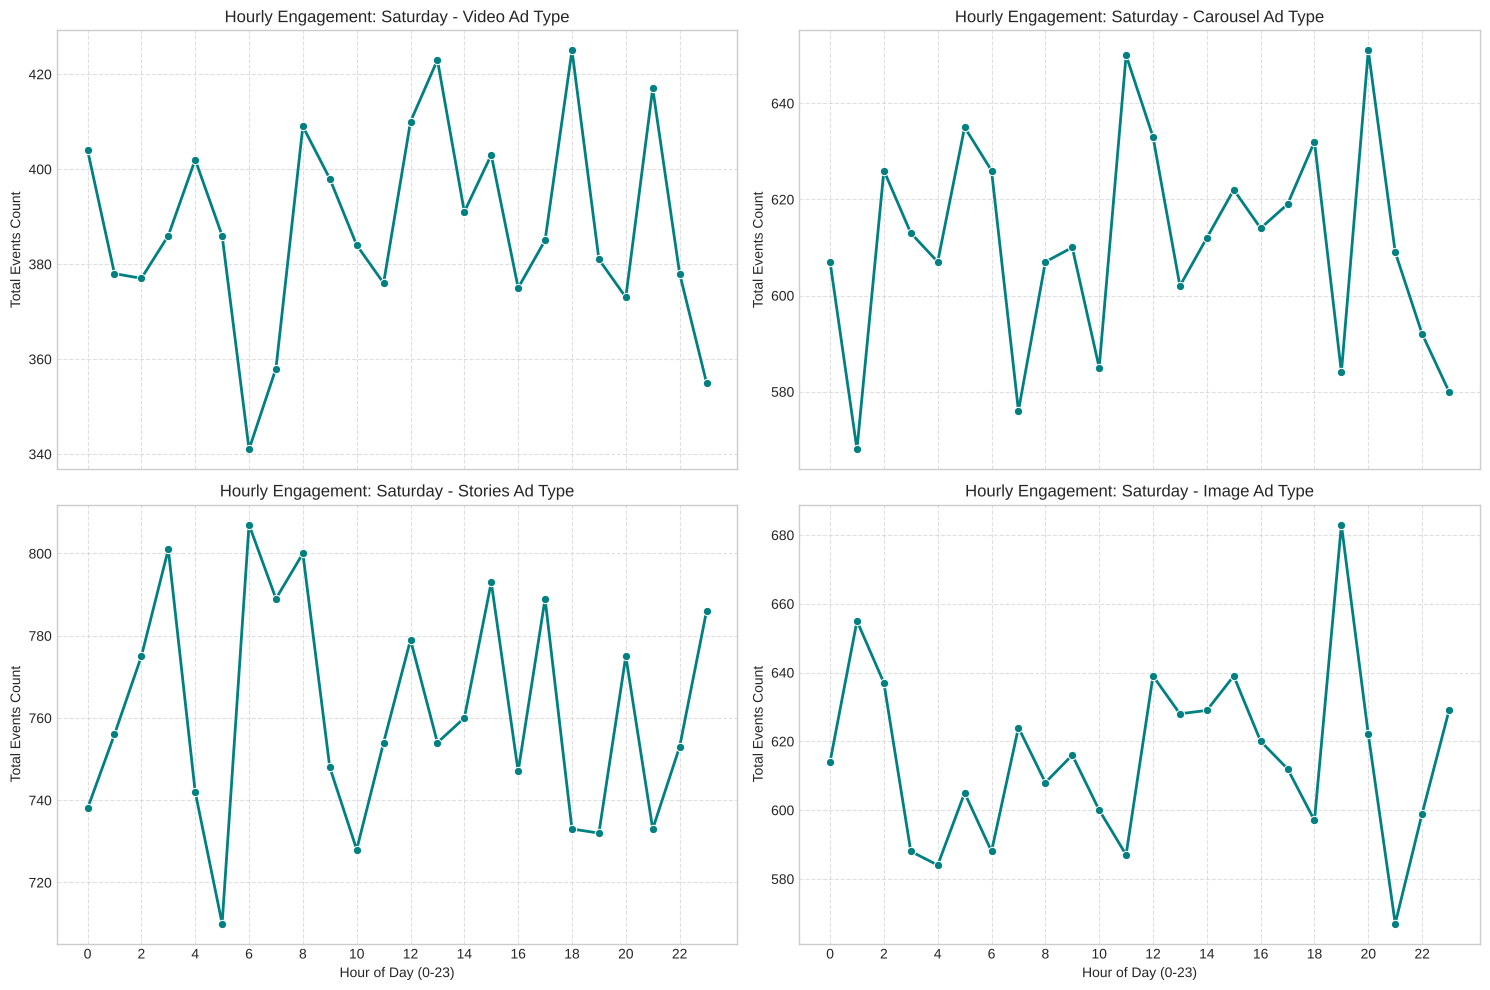

In [47]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == 'Saturday') &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color='teal',
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: Saturday - {title}", fontsize=12)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#Sunday

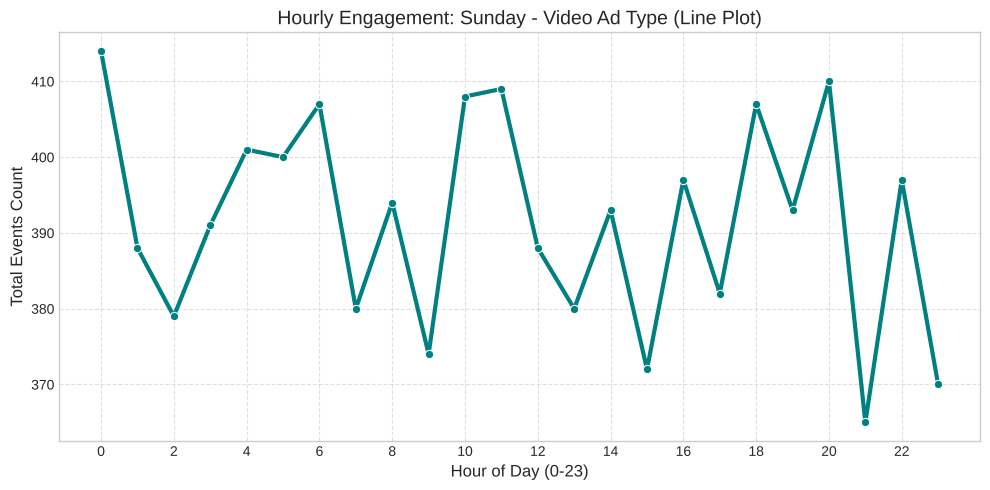

In [48]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Sunday') &
    (df_merged_prep['ad_type'] == 'Video')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Sunday - Video Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

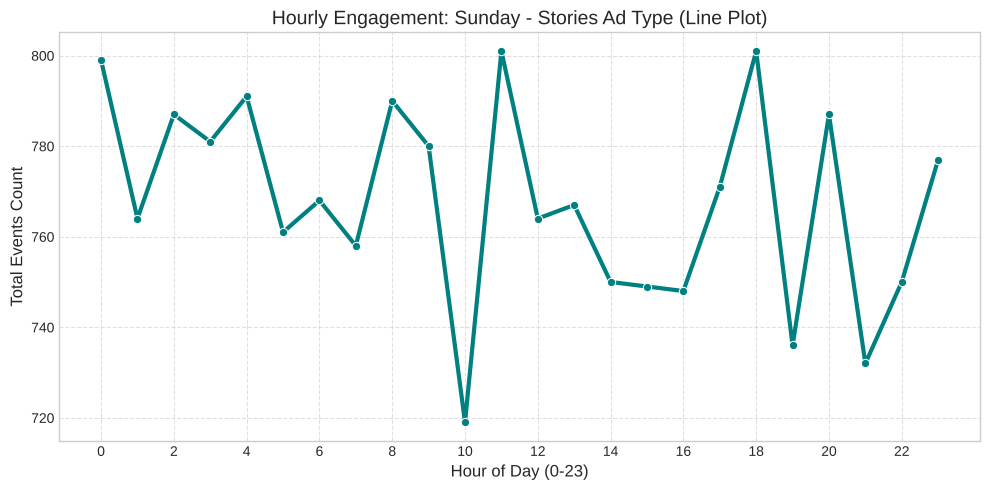

In [49]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Sunday') &
    (df_merged_prep['ad_type'] == 'Stories')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Sunday - Stories Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

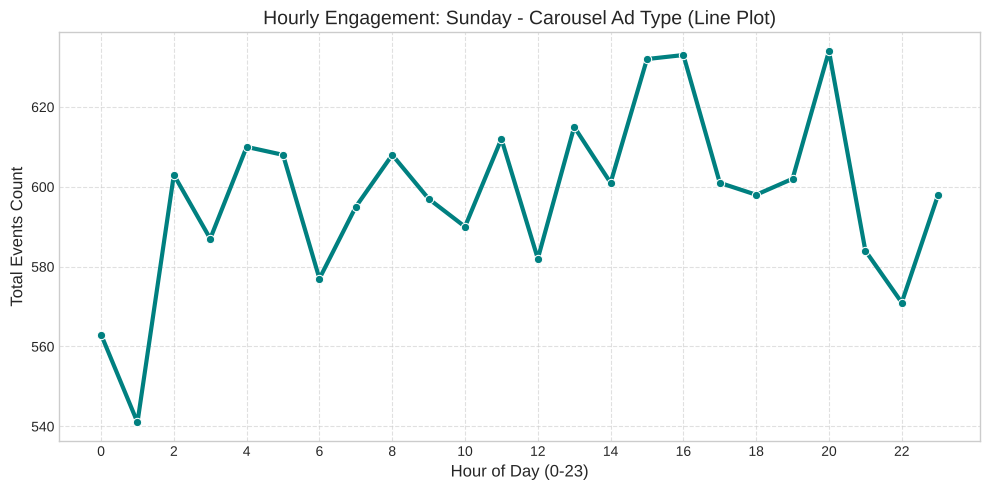

In [50]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Sunday') &
    (df_merged_prep['ad_type'] == 'Carousel')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Sunday - Carousel Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

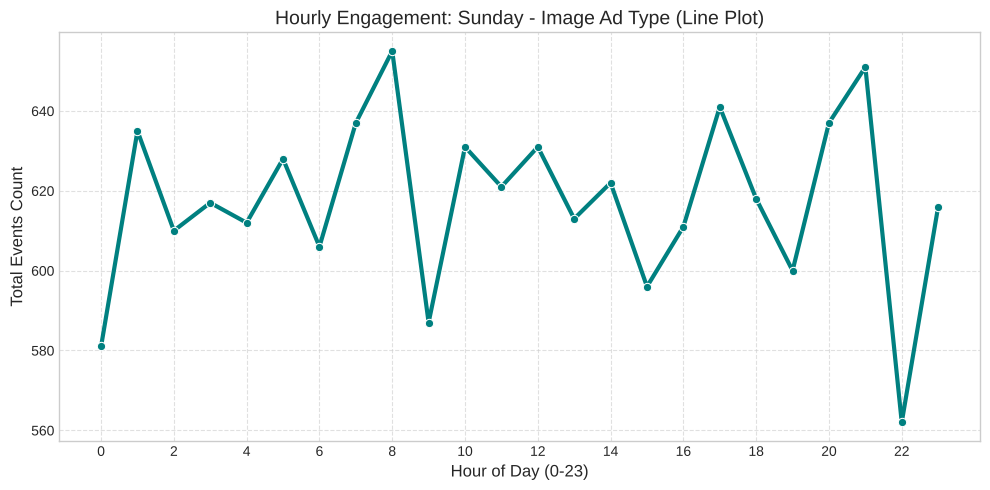

In [51]:
df_day_type = df_merged_prep[
    (df_merged_prep['day_of_week'] == 'Sunday') &
    (df_merged_prep['ad_type'] == 'Image')
]

agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=agg_data,
    x='hour_of_day',
    y='Total_Events_Count',
    marker='o',
    linewidth=3,
    color='teal'
)

plt.title("Hourly Engagement: Sunday - Image Ad Type (Line Plot)", fontsize=14)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Total Events Count", fontsize=12)
plt.xticks(range(0, 24, 2))
plt.grid(axis='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

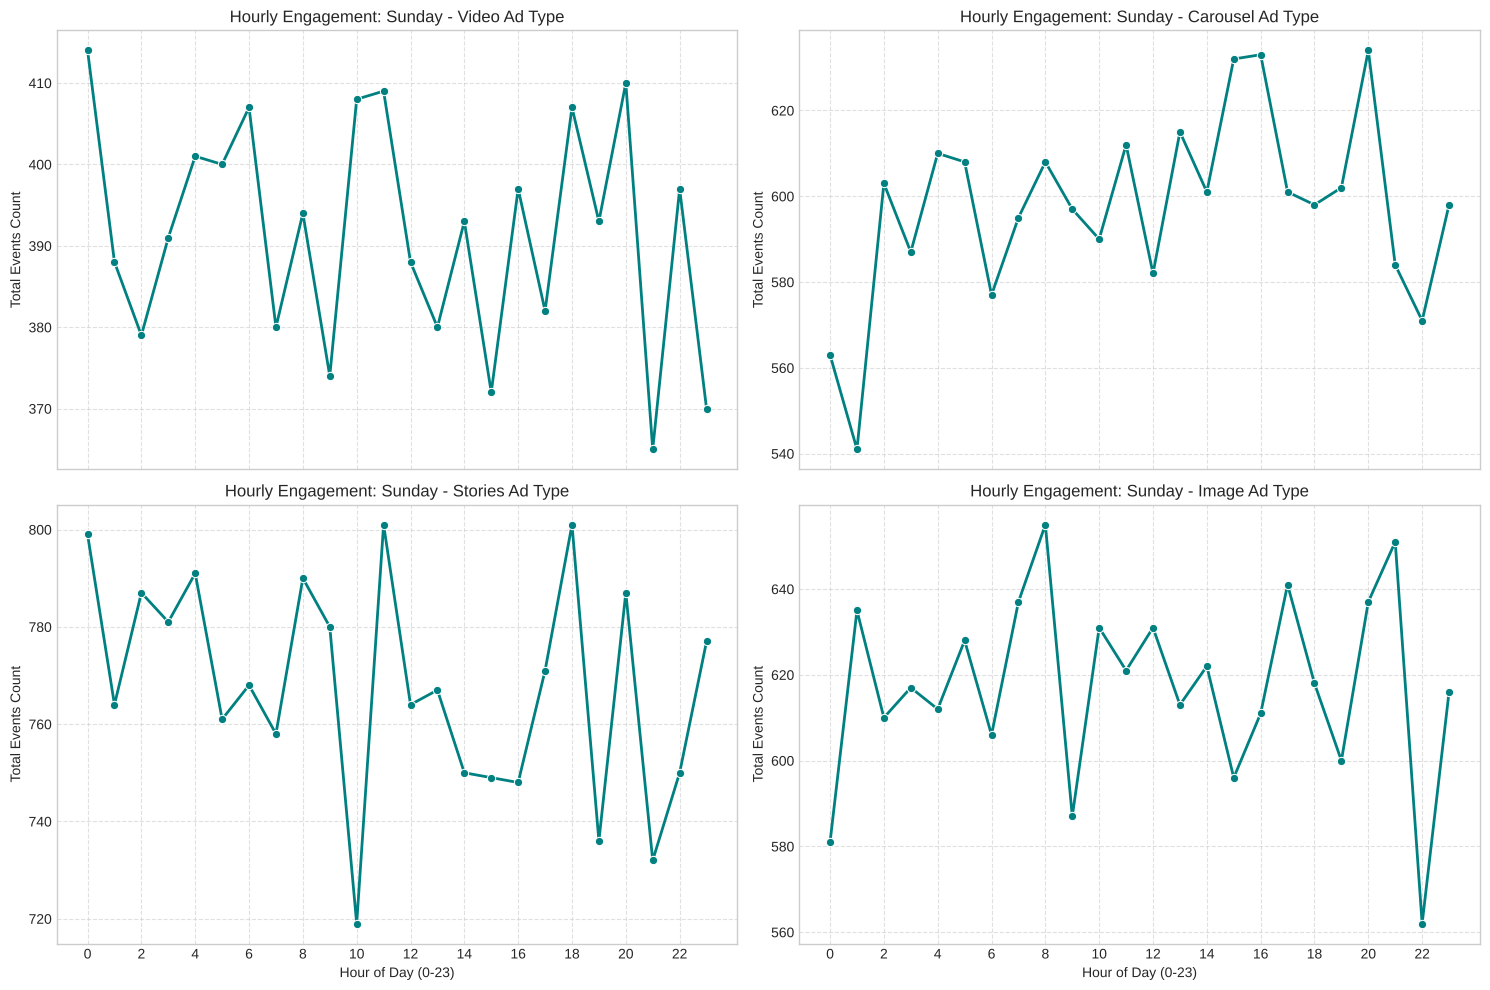

In [52]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == 'Sunday') &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color='teal',
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: Sunday - {title}", fontsize=12)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Week

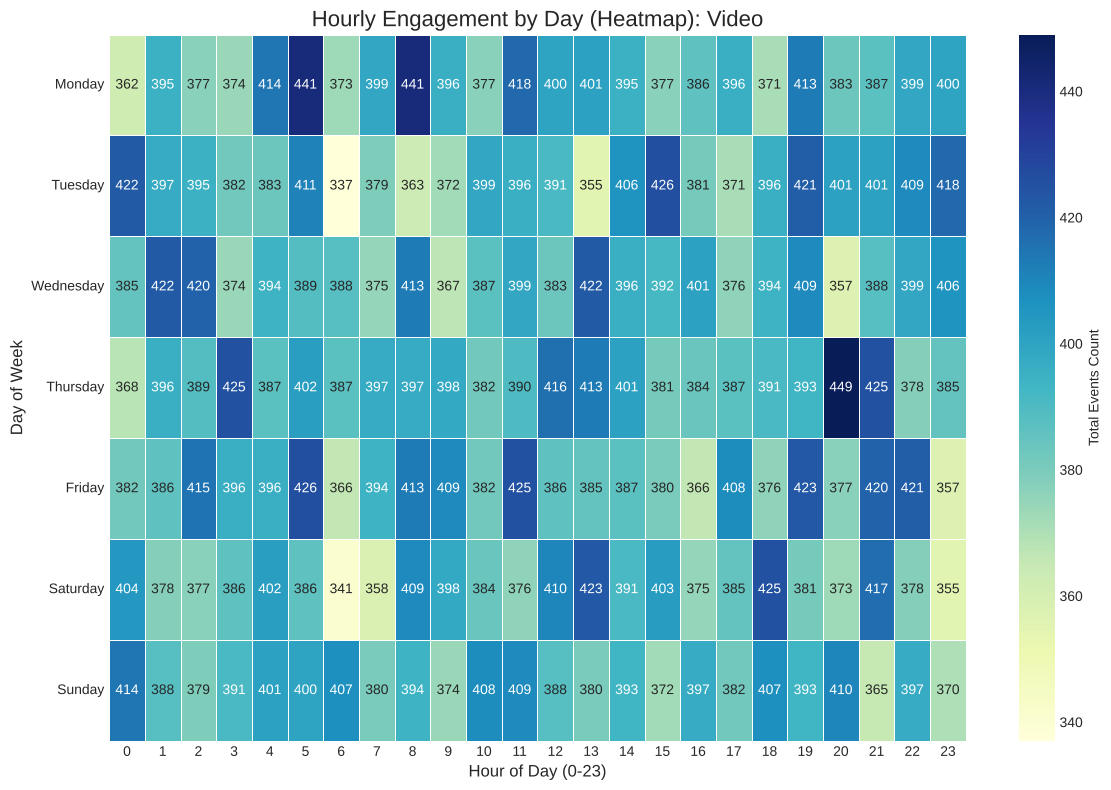

In [53]:
TARGET_AD_TYPE = 'Video'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# FACEBOOK AND IG

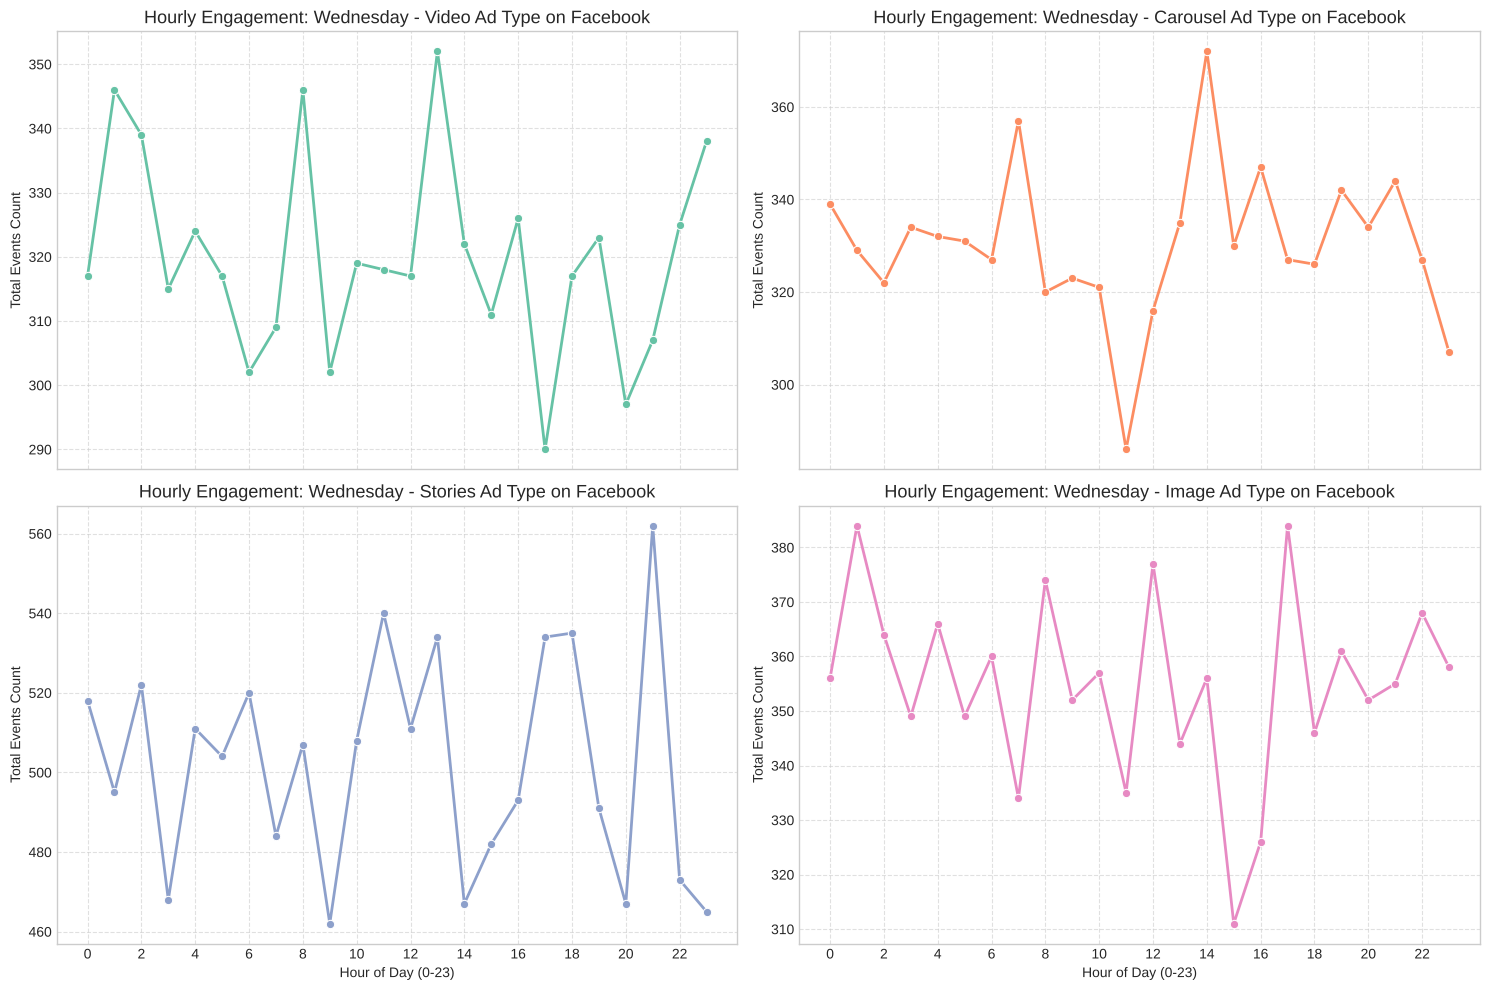

In [54]:
ad_types = ['Video', 'Carousel', 'Stories', 'Image']
titles = ['Video Ad Type', 'Carousel Ad Type', 'Stories Ad Type', 'Image Ad Type']

fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True, sharey=False)

TARGET_PLATFORM = 'Facebook'
TARGET_DAY = 'Wednesday'

for ax, ad_type, title in zip(axes.flatten(), ad_types, titles):
    df_day_type = df_merged_prep[
        (df_merged_prep['day_of_week'] == TARGET_DAY) &
        (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
        (df_merged_prep['ad_type'] == ad_type)
    ]

    agg_data = df_day_type.groupby('hour_of_day')['event_id'].count().reset_index()
    agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

    sns.lineplot(
        data=agg_data,
        x='hour_of_day',
        y='Total_Events_Count',
        marker='o',
        linewidth=2,
        color=plt.cm.Set2(ad_types.index(ad_type)),
        ax=ax
    )

    ax.set_title(f"Hourly Engagement: {TARGET_DAY} - {title} on {TARGET_PLATFORM}", fontsize=13)
    ax.set_xlabel("Hour of Day (0-23)", fontsize=10)
    ax.set_ylabel("Total Events Count", fontsize=10)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(axis='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Facebook


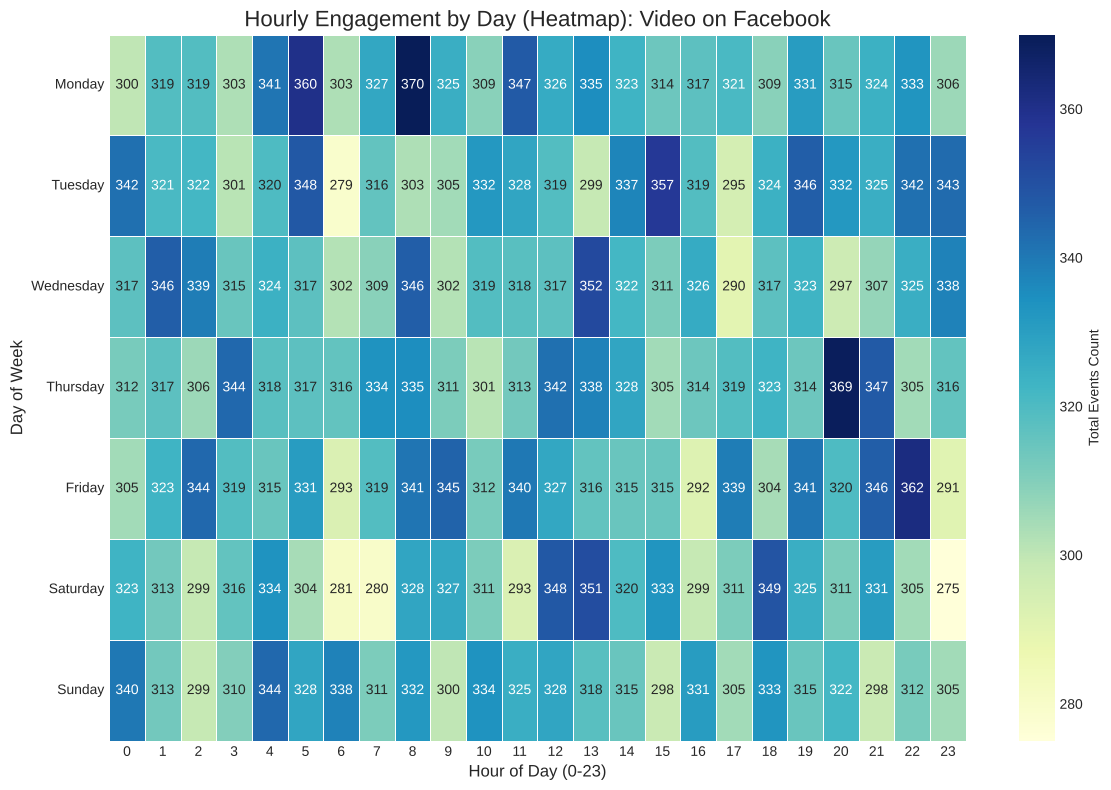

In [55]:
TARGET_PLATFORM = 'Facebook'
TARGET_AD_TYPE = 'Video'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

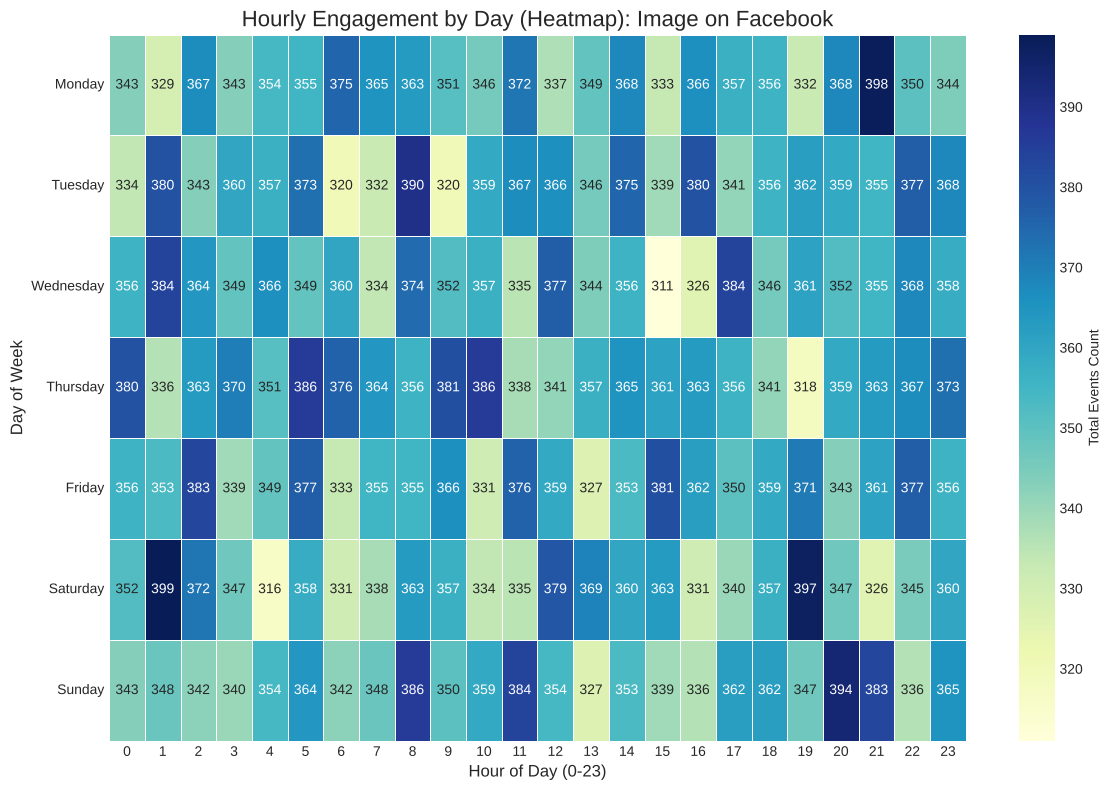

In [56]:
TARGET_PLATFORM = 'Facebook'
TARGET_AD_TYPE = 'Image'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

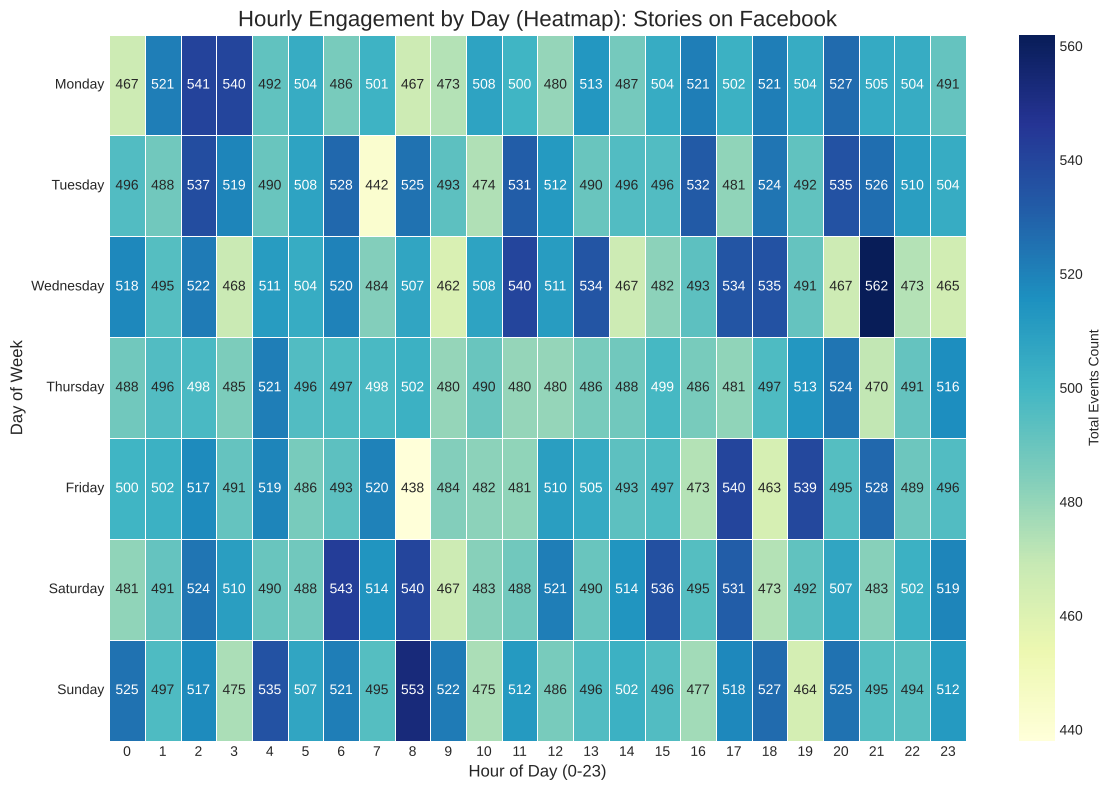

In [57]:
TARGET_PLATFORM = 'Facebook'
TARGET_AD_TYPE = 'Stories'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

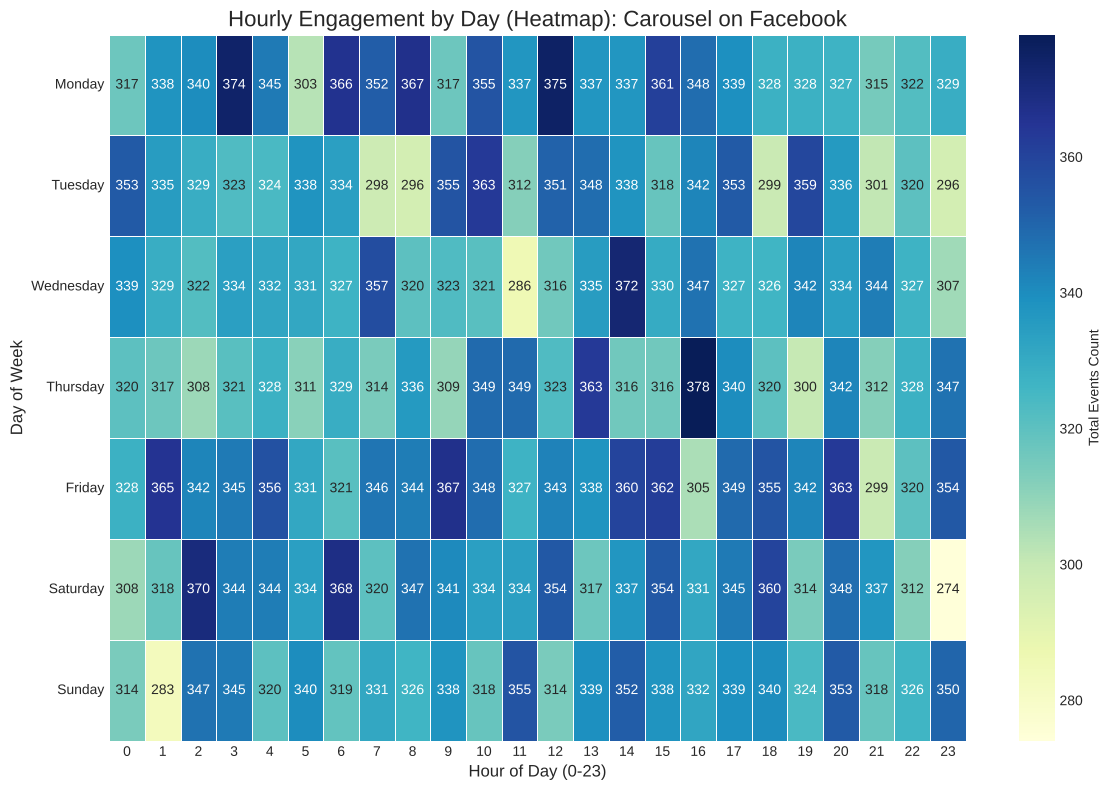

In [58]:
TARGET_PLATFORM = 'Facebook'
TARGET_AD_TYPE = 'Carousel'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Instragram

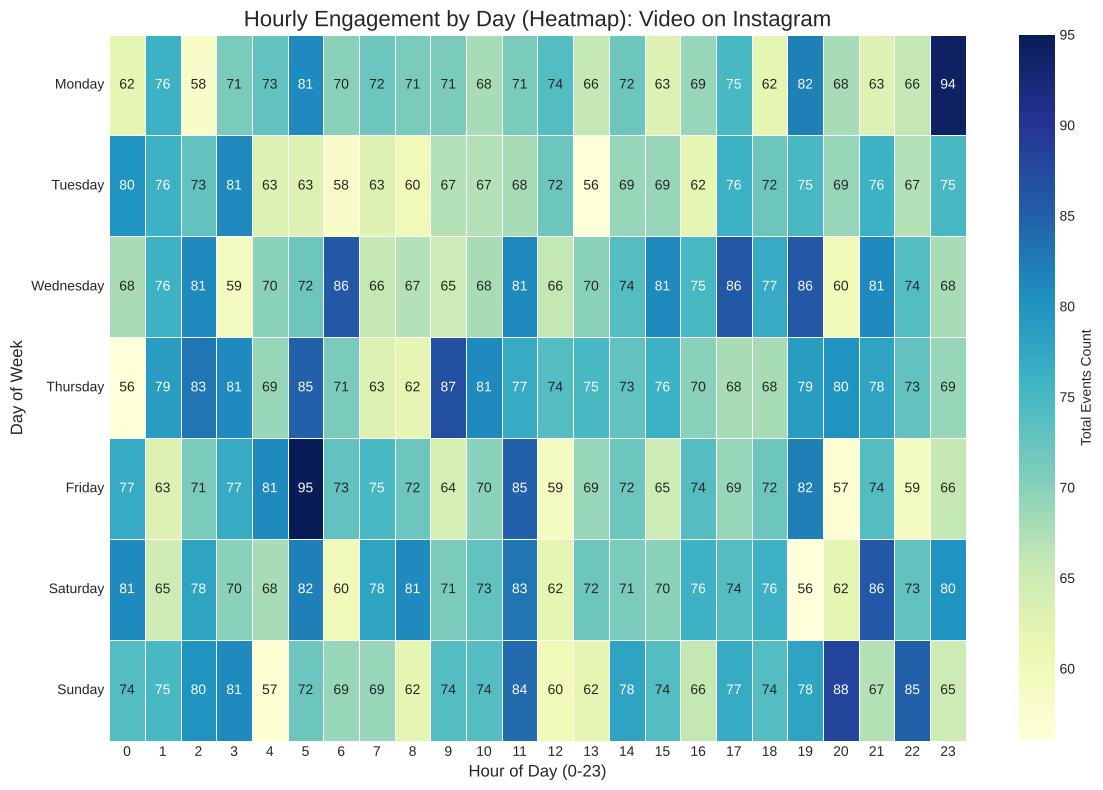

In [59]:
TARGET_PLATFORM = 'Instagram'
TARGET_AD_TYPE = 'Video'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

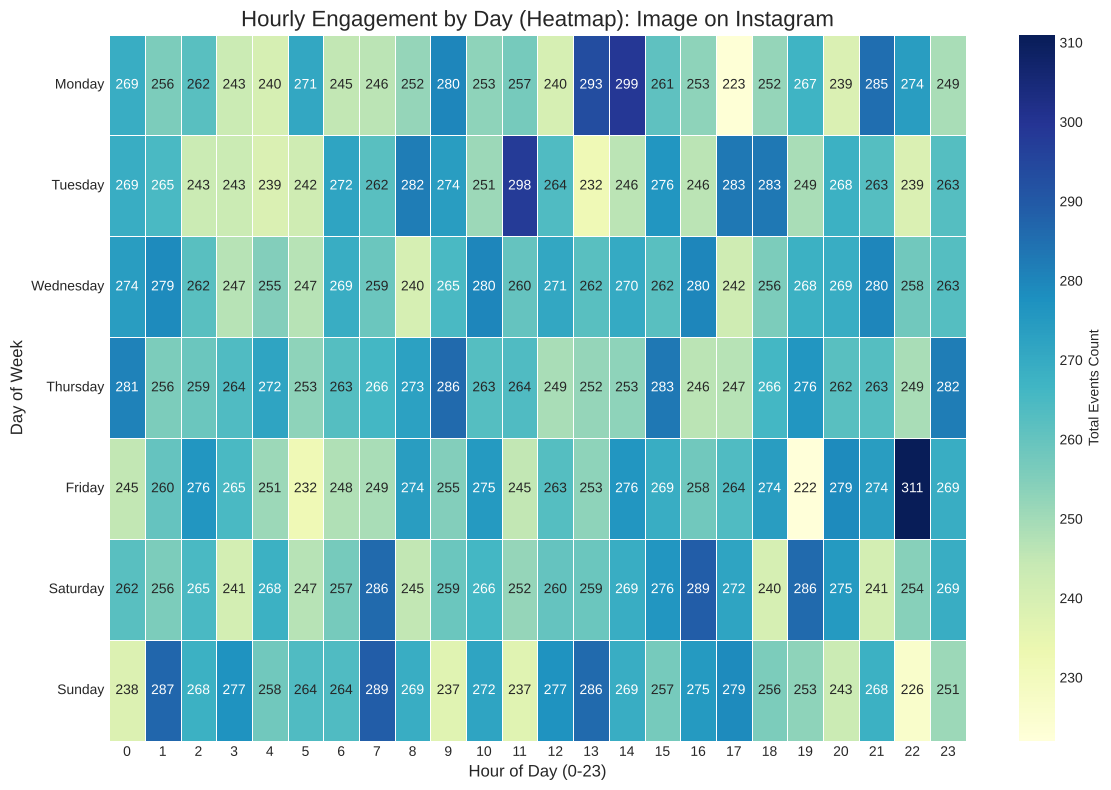

In [60]:
TARGET_PLATFORM = 'Instagram'
TARGET_AD_TYPE = 'Image'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

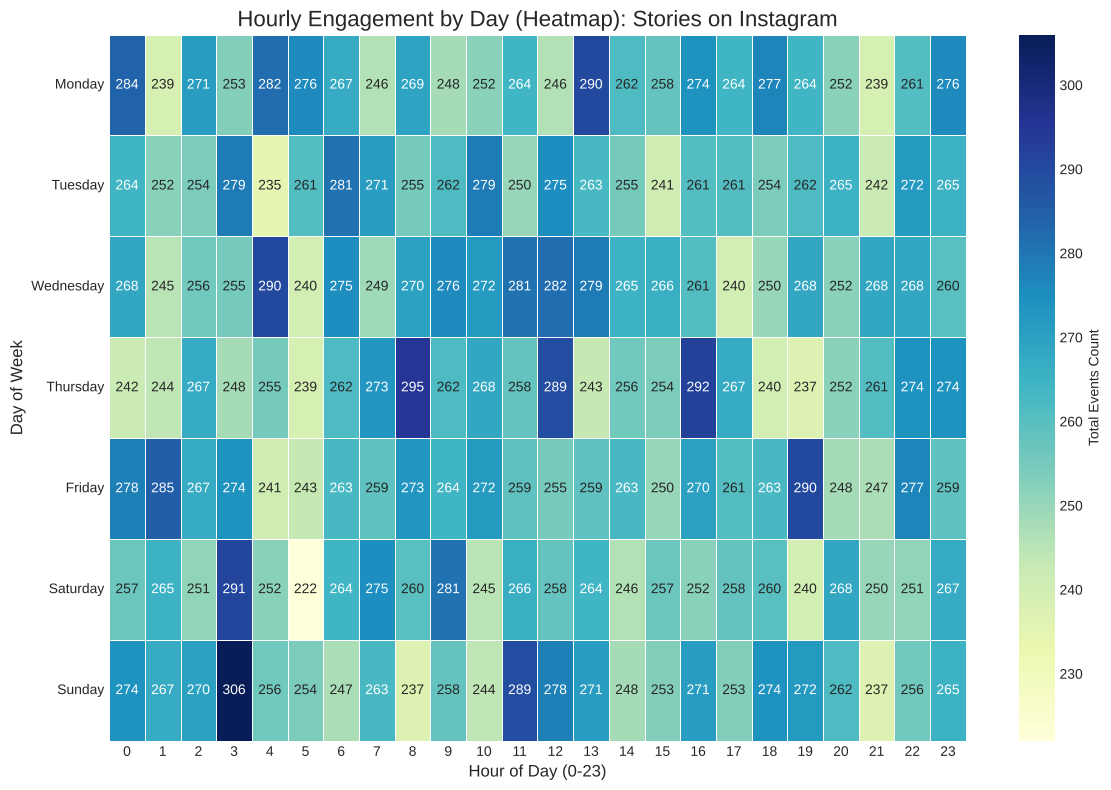

In [61]:
TARGET_PLATFORM = 'Instagram'
TARGET_AD_TYPE = 'Stories'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

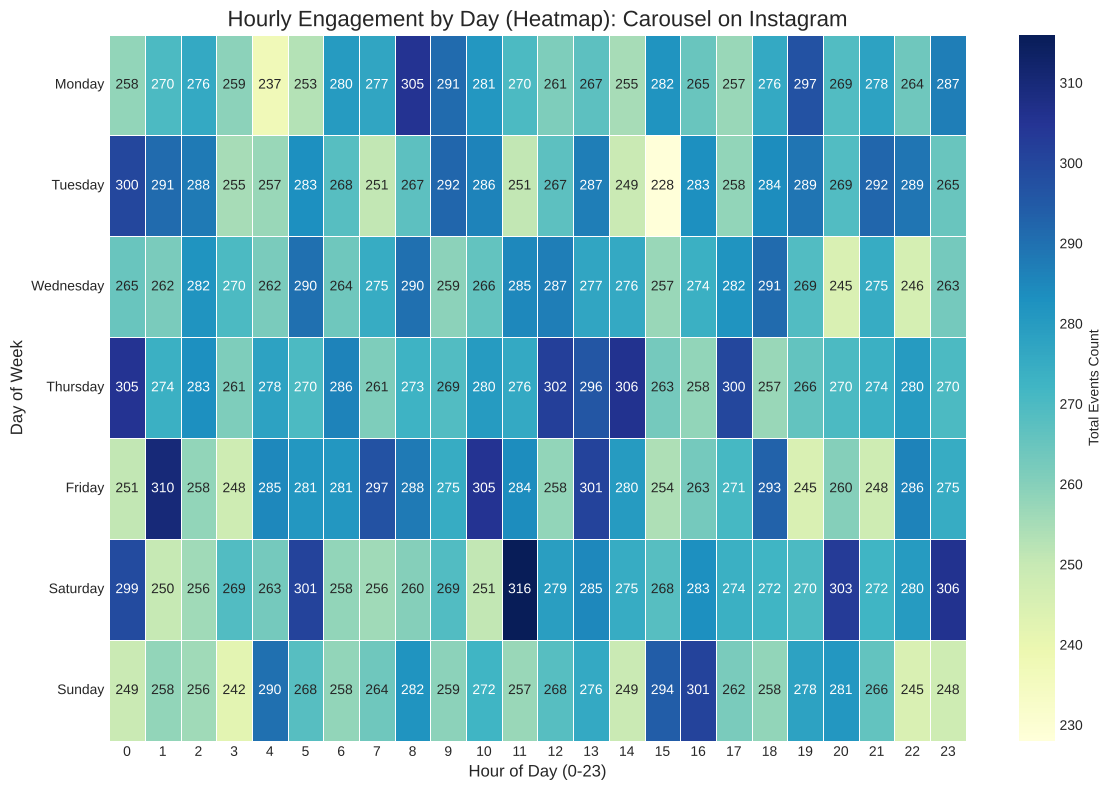

In [62]:
TARGET_PLATFORM = 'Instagram'
TARGET_AD_TYPE = 'Carousel'
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

df_platform = df_merged_prep[
    (df_merged_prep['ad_platform'] == TARGET_PLATFORM) &
    (df_merged_prep['ad_type'] == TARGET_AD_TYPE)
]

agg_data = df_platform.groupby(['hour_of_day', 'day_of_week'])['event_id'].count().reset_index()
agg_data.rename(columns={'event_id': 'Total_Events_Count'}, inplace=True)

agg_data['day_of_week'] = pd.Categorical(agg_data['day_of_week'], categories=day_order, ordered=True)

heatmap_data = agg_data.pivot_table(
    index='day_of_week',
    columns='hour_of_day',
    values='Total_Events_Count'
).fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(
    data=heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".0f",
    linewidths=.5,
    cbar_kws={'label': 'Total Events Count'},
    linecolor='white'
)

plt.title(f"Hourly Engagement by Day (Heatmap): {TARGET_AD_TYPE} on {TARGET_PLATFORM}", fontsize=16)
plt.xlabel("Hour of Day (0-23)", fontsize=12)
plt.ylabel("Day of Week", fontsize=12)
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



```
# This is formatted as code
```

# New Section

In [63]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
users_df_clean = users_df.drop_duplicates(subset=['user_id'])

df_merged = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')

df_merged = pd.merge(
    df_merged,
    users_df_clean[['user_id']],
    on='user_id',
    how='left'
)
final_columns_for_ml = [
    'event_id',
    'ad_platform',
    'ad_type',
    'day_of_week',
    'event_type',

]

df_final_ml_ready = df_merged[final_columns_for_ml].copy()

df_final_ml_ready

,event_id,ad_platform,ad_type,day_of_week,event_type
0,1,Facebook,Stories,Saturday,Like
1,2,Instagram,Carousel,Sunday,Share
2,3,Instagram,Carousel,Friday,Impression
3,4,Instagram,Image,Thursday,Impression
4,5,Instagram,Stories,Tuesday,Impression
...,...,...,...,...,...
399995,399996,Facebook,Carousel,Friday,Impression
399996,399997,Instagram,Carousel,Saturday,Impression
399997,399998,Facebook,Stories,Sunday,Click
399998,399999,Facebook,Stories,Friday,Impression


In [64]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
users_df_clean = users_df.drop_duplicates(subset=['user_id'])
campaigns_df_clean = campaigns_df.drop_duplicates(subset=['campaign_id'])

df_merged = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')
df_merged = pd.merge(
    df_merged,
    users_df_clean[['user_id', 'user_gender']],
    on='user_id',
    how='left'
)

df_merged = pd.merge(
    df_merged,
    campaigns_df_clean[['campaign_id', 'total_budget']],
    on='campaign_id',
    how='left'
)

df_engaged = df_merged[df_merged['event_type'].isin(['Click', 'Like', 'Share','Impression','Purchase'])].copy()

df_grouped = df_engaged.groupby(['day_of_week', 'time_of_day', 'ad_platform', 'ad_type', 'target_gender', 'campaign_id']).agg(
    engaged=('event_type', 'count')
).reset_index()

df_grouped = pd.merge(
    df_grouped,
    campaigns_df_clean[['campaign_id', 'total_budget']],
    on='campaign_id',
    how='left'
)

final_columns_for_ml = [
    'day_of_week',
    'time_of_day',
    'ad_platform',
    'ad_type',
    'target_gender',
    'total_budget',
    'engaged'
]

df_final_ml_ready = df_grouped[final_columns_for_ml].copy()

display(df_final_ml_ready)

,day_of_week,time_of_day,ad_platform,ad_type,target_gender,total_budget,engaged
0,Friday,Afternoon,Facebook,Carousel,All,40094.07,73
1,Friday,Afternoon,Facebook,Carousel,All,21855.42,74
2,Friday,Afternoon,Facebook,Carousel,All,98904.66,66
3,Friday,Afternoon,Facebook,Carousel,All,56692.87,69
4,Friday,Afternoon,Facebook,Carousel,All,59264.68,75
...,...,...,...,...,...,...,...
5091,Wednesday,Night,Instagram,Video,All,35743.40,75
5092,Wednesday,Night,Instagram,Video,Female,45326.60,63
5093,Wednesday,Night,Instagram,Video,Female,81744.53,77
5094,Wednesday,Night,Instagram,Video,Female,59264.68,62


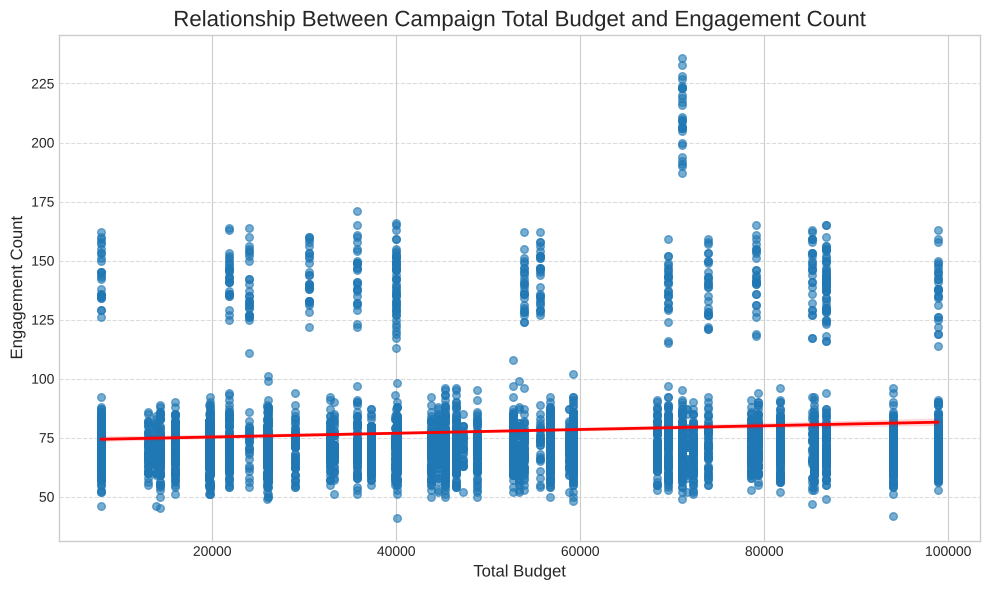

In [65]:
plt.figure(figsize=(10, 6))
sns.regplot(
    x='total_budget',
    y='engaged',
    data=df_final_ml_ready,
    scatter_kws={'alpha':0.6, 's':30, 'color':'#1f77b4'},
    line_kws={'color':'red', 'linewidth': 2}
)

plt.title('Relationship Between Campaign Total Budget and Engagement Count', fontsize=16)
plt.xlabel('Total Budget', fontsize=12)
plt.ylabel('Engagement Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

/tmp/ipykernel_588/3713011394.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


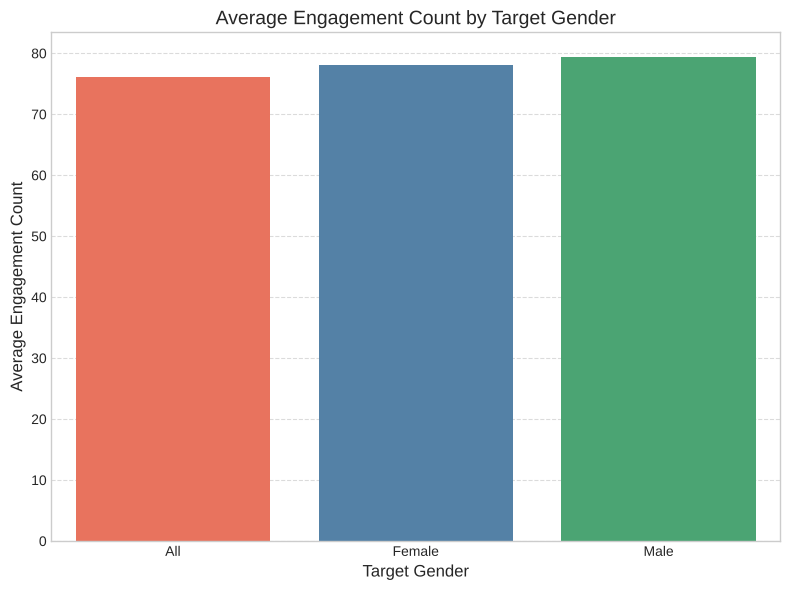

In [66]:
df_gender_engaged = df_final_ml_ready.groupby('target_gender').agg(
    avg_engaged=('engaged', 'mean')
).reset_index()

plt.figure(figsize=(8, 6))
sns.barplot(
    x='target_gender',
    y='avg_engaged',
    data=df_gender_engaged,
    palette=['#FF6347', '#4682B4', '#3CB371']
)

plt.title('Average Engagement Count by Target Gender', fontsize=14)
plt.xlabel('Target Gender', fontsize=12)
plt.ylabel('Average Engagement Count', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Summarry

สรุปแล้ว โดยรวม เวลา , วัน , ประเภทโฆษณา และ แพลตฟอร์ม นั้นมีผลต่อยอด engagement ของ user หากรับรู้ว่าควรยิง ads ประเภทไหนในเวลาและแพลตฟอร์มไหนก็จะทำให้ยอด engagement ของ user สูงขึ้นและสามารถรถ budget ลงได้ เนื่องจาก heatmap นั้นโชว์ว่ามีความแตกต่างกันในแต่ละช่วงเวลาอย่างชัดเจน

# For ML


In [67]:
ads_df_clean = ads_df.drop_duplicates(subset=['ad_id'])
users_df_clean = users_df.drop_duplicates(subset=['user_id'])
campaigns_df_clean = campaigns_df.drop_duplicates(subset=['campaign_id'])

ad_events_df['timestamp'] = pd.to_datetime(ad_events_df['timestamp'])
ad_events_df['hour_of_day'] = ad_events_df['timestamp'].dt.hour
campaigns_df_clean['start_date'] = pd.to_datetime(campaigns_df_clean['start_date'])
campaigns_df_clean['end_date'] = pd.to_datetime(campaigns_df_clean['end_date'])

campaigns_df_clean['start_month'] = campaigns_df_clean['start_date'].dt.month
campaigns_df_clean['start_day'] = campaigns_df_clean['start_date'].dt.day
campaigns_df_clean['end_month'] = campaigns_df_clean['end_date'].dt.month
campaigns_df_clean['end_day'] = campaigns_df_clean['end_date'].dt.day

df_merged = pd.merge(ad_events_df, ads_df_clean, on='ad_id', how='left')

df_merged = pd.merge(
    df_merged,
    campaigns_df_clean[['campaign_id', 'name', 'duration_days', 'start_month', 'start_day', 'end_month', 'end_day']],
    on='campaign_id',
    how='left'
).rename(columns={'name': 'campaign_name'})

df_merged = pd.merge(
    df_merged,
    users_df_clean[['user_id']],
    on='user_id',
    how='left'
)
final_columns_for_ml = [
    'event_id',
    'ad_platform',
    'ad_type',
    'day_of_week',
    'hour_of_day',
    'event_type',
    'campaign_name',
    'start_month',
    'start_day',
    'end_month',
    'end_day',
    'duration_days'
]

df_final_ml_ready = df_merged[final_columns_for_ml].copy()

df_final_ml_ready

,event_id,ad_platform,ad_type,day_of_week,hour_of_day,event_type,campaign_name,start_month,start_day,end_month,end_day,duration_days
0,1,Facebook,Stories,Saturday,0,Like,Campaign_9_Launch,5,25,7,13,49
1,2,Instagram,Carousel,Sunday,8,Share,Campaign_26_Winter,4,1,6,17,77
2,3,Instagram,Carousel,Friday,0,Impression,Campaign_10_Winter,5,17,7,21,65
3,4,Instagram,Image,Thursday,19,Impression,Campaign_14_Summer,4,15,6,4,50
4,5,Instagram,Stories,Tuesday,8,Impression,Campaign_2_Launch,4,16,7,7,82
...,...,...,...,...,...,...,...,...,...,...,...,...
399995,399996,Facebook,Carousel,Friday,22,Impression,Campaign_1_Launch,5,25,7,23,59
399996,399997,Instagram,Carousel,Saturday,14,Impression,Campaign_44_Q3,7,14,9,22,70
399997,399998,Facebook,Stories,Sunday,13,Click,Campaign_33_Summer,4,8,7,4,87
399998,399999,Facebook,Stories,Friday,2,Impression,Campaign_8_Q3,2,25,4,7,41
